---
# <div align="center"><font color='blue'> COSC 2779/2972 | Deep Learning </font></div>
## <div align="center"><font color='blue'> Assignment 1: Drone Marshalling Gesture Classifier </font></div>
### <div align="center"> Student: s4271512 </div>
---

## Task

The task is to classify one gesture as one of 13 classes. Each gesture contains five frames. The
provided segmenter creates these five frame instances.

The model must meet the following constraints.

- It must use a 2-D convolutional backbone.
- It must not use recurrent networks, 3-D convolution, or temporal attention.
- It must use all five frames.
- It must be small enough for plausible real time inference on an embedded board.
- ImageNet pretraining and standard augmentation are allowed.
- External gesture and action datasets are not allowed.

Part B gives a separate recommendation about deployment.

## Method

The method follows the Week 6 lab and Ng's *Machine Learning Yearning*. The notebook defines a
target, explores the data, builds a baseline, compares models, analyses errors, and evaluates the
final model on a locked test set. Each main decision is supported by data, results, or course
material.


In [1]:
import json, time, random, zipfile
from pathlib import Path
from collections import Counter
from contextlib import contextmanager

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# CPU works but makes the end-to-end fine-tuning in Sections 7 and 9 very slow.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

AMP_ENABLED = (device.type == 'cuda')   # mixed precision, where the hardware supports it
print('Mixed precision (AMP) enabled:', AMP_ENABLED)

Using device: cuda
Mixed precision (AMP) enabled: True


In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# A dedicated generator for anything that needs its own reproducible stream
# (e.g. DataLoader shuffling) without disturbing the global RNG state used
# for model init.
g = torch.Generator().manual_seed(SEED)

In [3]:
# Section timer -- reports how long each stage takes. Bookkeeping only; no
# effect on results.
_section_times = {}

@contextmanager
def section(name):
    t0 = time.perf_counter()
    print(f'--- {name} ---')
    yield
    dt = time.perf_counter() - t0
    _section_times[name] = dt
    print(f'[{name} finished in {dt/60:.1f} min]')

def print_timing_summary():
    print(f'{"Section":<45}{"Time":>10}')
    print('=' * 55)
    total = 0.0
    for name, dt in _section_times.items():
        print(f'{name:<45}{dt/60:>9.1f}m')
        total += dt
    print('=' * 55)
    print(f'{"TOTAL":<45}{total/60:>9.1f}m')

In [4]:
# ---------------------------------------------------------------------------
# Locate the dataset: prefer an already-unpacked `data_resized/`, otherwise
# unzip the supplied archive once and reuse it.
# ---------------------------------------------------------------------------
ASSIGNMENT_ROOT = Path.cwd()
if ASSIGNMENT_ROOT.name != 'Assignment 1' and (ASSIGNMENT_ROOT / 'Assignment 1').exists():
    ASSIGNMENT_ROOT = ASSIGNMENT_ROOT / 'Assignment 1'

CANDIDATE_DATA_DIRS = [
    ASSIGNMENT_ROOT / 'data_resized',
    ASSIGNMENT_ROOT / 'Data from Assignment' / 'data_resized',
    Path.home() / 'SageMaker' / 'course-files' / 'COSC2779-DATA' / 'data_resized',
]
CANDIDATE_ZIPS = [
    ASSIGNMENT_ROOT / 'Data from Assignment' / 'A1_data_2026.zip',
    ASSIGNMENT_ROOT / 'A1_data_2026.zip',
    Path.home() / 'SageMaker' / 'A1_data_2026.zip',
    Path.home() / 'SageMaker' / 'course-files' / 'COSC2779-DATA' / 'A1_data_2026.zip',
]

def resolve_data_root():
    for d in CANDIDATE_DATA_DIRS:
        if d.exists() and any(d.iterdir()):
            print('Using already-unpacked data at:', d)
            return d
    for z in CANDIDATE_ZIPS:
        if z.exists():
            target = z.parent / 'data_resized'
            print(f'Unpacking {z} -> {target} (one-off, ~2 min) ...')
            with zipfile.ZipFile(z) as zf:
                members = [n for n in zf.namelist()
                           if not n.startswith('__MACOSX') and n.lower().endswith('.png')]
                zf.extractall(z.parent, members=members)
            unpacked = z.parent / 'data_resized'
            print('Done. Using:', unpacked)
            return unpacked
    raise FileNotFoundError(
        'Could not find data_resized/ or A1_data_2026.zip in any candidate location:\n'
        + '\n'.join(str(p) for p in CANDIDATE_DATA_DIRS + CANDIDATE_ZIPS)
        + '\nPlace the assignment zip in "Assignment 1/Data from Assignment/" and re-run.'
    )

DATA_ROOT = resolve_data_root()
CACHE_DIR = ASSIGNMENT_ROOT / 'cache'
CACHE_DIR.mkdir(exist_ok=True)

Using already-unpacked data at: /home/ec2-user/SageMaker/course-files/COSC2779-DATA/data_resized


In [5]:
CLASS_NAMES = sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir())
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
N_FRAMES = 5          # every instance is exactly 5 frames (verified in EDA below)
IMG_SIZE = 160         # matches the Week 6 lecture notebook's MobileNetV2 input size

print(f'{NUM_CLASSES} classes:', CLASS_NAMES)

13 classes: ['AllClear', 'HaveCommand', 'Hover', 'Land', 'LandingDirection', 'MoveAhead', 'MoveDownward', 'MoveToLeft', 'MoveToRight', 'MoveUpward', 'NotClear', 'SlowDown', 'WaveOff']


---
## 1. Data ingest and caching

Each frame is decoded once and stored in a cache. All later cells use this cache. This reduces
repeated file loading and keeps the inputs consistent between experiments.

### Input pipelines

The subject occupies about one fifth of the frame height, as shown in Section 2. A direct resize to
160 by 160 pixels leaves little detail around the arms. Section 6 compares three input pipelines.

| Pipeline | Operation | Reason |
|---|---|---|
| `full` | resize the complete frame | baseline |
| `center` | crop the centre 55%, then resize | the subject is centred in each clip |
| `motion` | estimate a crop from movement across the five frames, then resize | region proposal method from Week 5 Lecture Part 1, slides 51 to 52 |

The `motion` pipeline computes the temporal range of each pixel. It thresholds this range and forms a
bounding box around the moving region. Invalid boxes use the centre crop. The fallback rate is
reported in Section 2.

All crops are calculated at the original resolution. The cropped image is resized afterwards.


In [6]:
import re
from PIL import Image

# Trailing frame number, with or without a separator in front of it, so this
# works for both the assignment's `S5_land_HD_instance13_1.png` and a plainly
# named `1.png`. Files with no trailing number fall back to name order.
FRAME_RE = re.compile(r'(\d+)\s*\.png$', re.IGNORECASE)

def _frame_key(path):
    m = FRAME_RE.search(path.name)
    return (0, int(m.group(1))) if m else (1, path.name.lower())

def parse_instances(data_root):
    """Return one record per instance, each holding its frame paths in frame order.

    An *instance* is any directory that directly contains PNG files, found at
    whatever depth it sits. That covers the assignment layout
    (`<Class>/<Subject>/Instance##/*.png`) and equally a flatter one
    (`<Class>/<attempt>/*.png`), which is what the webcam clips in Section 9
    use -- the earlier fixed-depth version silently returned nothing for the
    latter. `subject` is the folder directly under the class when the tree is
    deeper than one level, else the instance folder's own name."""
    def visible(path, root):
        # Jupyter drops `.ipynb_checkpoints` folders (holding a partial copy of
        # whatever was opened) anywhere a file is edited, including inside this
        # tree. Those are not gesture instances.
        return not any(part.startswith('.') for part in path.relative_to(root).parts)

    records = []
    for cls_dir in sorted(d for d in data_root.iterdir() if d.is_dir() and not d.name.startswith('.')):
        inst_dirs = [d for d in cls_dir.rglob('*')
                     if d.is_dir() and visible(d, cls_dir)
                     and any(f for f in d.glob('*.png') if not f.name.startswith('.'))]
        for inst_dir in sorted(inst_dirs):
            frames_sorted = sorted((f for f in inst_dir.glob('*.png') if not f.name.startswith('.')),
                                    key=_frame_key)
            if len(frames_sorted) != N_FRAMES:
                # Warn and skip rather than raise: one malformed folder should not
                # abort the whole notebook. Section 1 separately asserts that the
                # assignment dataset yields exactly 5 frames for every instance.
                print(f'  WARNING: skipping {inst_dir} -- {len(frames_sorted)} frames, expected {N_FRAMES}')
                continue
            rel = inst_dir.relative_to(cls_dir).parts
            records.append({
                'class': cls_dir.name,
                'subject': rel[0] if len(rel) > 1 else inst_dir.name,
                'instance': inst_dir.name,
                'frame_paths': [str(f) for f in frames_sorted],
            })
    return records

instances = parse_instances(DATA_ROOT)
print(f'Found {len(instances)} instances')

# Every instance must be exactly 5 frames -- assert rather than assume, since a
# silently-short instance would corrupt the fixed-size (5, C, H, W) tensor below.
bad = [r for r in instances if len(r['frame_paths']) != N_FRAMES]
assert not bad, f'{len(bad)} instances do not have exactly {N_FRAMES} frames: {bad[:3]}'
print(f'All instances have exactly {N_FRAMES} frames. OK.')

Found 1059 instances
All instances have exactly 5 frames. OK.


In [7]:
CACHE_INDEX = CACHE_DIR / 'index.json'
PIPELINES = ('full', 'center', 'motion')
CACHE_FRAMES = {p: CACHE_DIR / f'frames_{p}_{IMG_SIZE}.npy' for p in PIPELINES}

CENTER_CROP_FRAC = 0.55   # keep the middle 55% -- chosen from the visual check in Section 2
MOTION_MARGIN    = 0.30   # expand the motion box by 30% of its size on every side
MOTION_MIN_FRAC  = 0.15   # if the proposed box is smaller than this, fall back to centre crop
MOTION_MAX_FRAC  = 0.85   # ...or larger than this (i.e. the proposal found nothing useful)

def _square_box(cx, cy, half, W, H):
    """Clamp a square box of half-width `half` centred at (cx, cy) into the image."""
    half = max(half, 8)
    half = min(half, min(W, H) / 2)
    cx = min(max(cx, half), W - half)
    cy = min(max(cy, half), H - half)
    return int(cx - half), int(cy - half), int(cx + half), int(cy + half)

def _smooth1d(v, k=15):
    return np.convolve(v, np.ones(k) / k, mode='same')

def motion_box(frames_native):
    """Traditional-CV region proposal (Week 5 Lecture Part 1, slides 51-52).

    The subject is the main thing that moves across an instance's 5 frames, so
    the per-pixel temporal range |max_t - min_t| is high on the person (mostly
    the arms) and low on the static road/field/sky.

    Two details matter in practice. First, these clips carry a non-trivial
    ambient motion level (slight camera drift, changing light, compression
    noise), so a raw threshold on the range picks up the whole frame -- the
    90th-percentile value is subtracted off as a noise floor first. Second,
    scattered surviving pixels would still blow a min/max bounding box out to
    the full frame, so the box is taken from the smoothed row/column *profiles*
    of the motion map: summing along each axis accumulates the subject's
    contiguous motion while isolated noise averages away.

    Returns a square (x0, y0, x1, y1) box in native pixel coordinates, or None
    if the result looks degenerate -- in which case the caller falls back to the
    plain centre crop rather than trusting a bad proposal."""
    g = frames_native.astype(np.float32).mean(axis=-1)          # (5, H, W) greyscale
    m = g.max(axis=0) - g.min(axis=0)                           # per-pixel temporal range
    H, W = m.shape

    m = np.clip(m - np.percentile(m, 90), 0, None)              # subtract ambient motion
    if m.sum() < 1e-6:
        return None

    def span(profile):
        p = _smooth1d(profile)
        if p.max() <= 0:
            return None
        idx = np.nonzero(p > p.max() * 0.25)[0]
        return (idx[0], idx[-1]) if len(idx) else None

    cs, rs = span(m.sum(axis=0)), span(m.sum(axis=1))
    if cs is None or rs is None:
        return None
    x0, x1 = cs
    y0, y1 = rs
    bw, bh = x1 - x0, y1 - y0
    if bw < 4 or bh < 4:
        return None

    half = max(bw, bh) * (0.5 + MOTION_MARGIN)
    frac = (2 * half) / min(W, H)
    if frac < MOTION_MIN_FRAC or frac > MOTION_MAX_FRAC:
        return None
    return _square_box((x0 + x1) / 2, (y0 + y1) / 2, half, W, H)

def center_box(W, H):
    half = min(W, H) * CENTER_CROP_FRAC / 2
    return _square_box(W / 2, H / 2, half, W, H)

def decode_instances(records, size=IMG_SIZE, verbose=False, pipelines=PIPELINES):
    """Decode instance records into one (n, 5, size, size, 3) uint8 array per
    pipeline, in a single pass over the PNGs.

    All three crops are computed at the images' NATIVE resolution and only then
    resized down to `size`. Cropping after downsampling would recover no detail
    at all -- the point of cropping here is to spend the 160x160 budget on the
    person instead of on the road. Shared with the webcam loader in Section 9,
    so there is exactly one place that turns file paths into pixels."""
    n = len(records)
    out = {p: np.empty((n, N_FRAMES, size, size, 3), dtype=np.uint8) for p in pipelines}
    n_motion_fallback = 0
    t0 = time.perf_counter()
    for i, rec in enumerate(records):
        assert len(rec['frame_paths']) == N_FRAMES, \
            f'{rec["instance"]} has {len(rec["frame_paths"])} frames, expected {N_FRAMES}'
        native = np.stack([np.asarray(Image.open(p).convert('RGB'), dtype=np.uint8)
                            for p in rec['frame_paths']])          # (5, H, W, 3)
        H, W = native.shape[1:3]

        boxes = {}
        if 'center' in pipelines or 'motion' in pipelines:
            boxes['center'] = center_box(W, H)
        if 'motion' in pipelines:
            mb = motion_box(native)
            if mb is None:
                mb = boxes['center']
                n_motion_fallback += 1
            boxes['motion'] = mb

        for f in range(N_FRAMES):
            img = Image.fromarray(native[f])
            for p in pipelines:
                im = img if p == 'full' else img.crop(boxes[p])
                out[p][i, f] = np.asarray(im.resize((size, size), Image.BILINEAR), dtype=np.uint8)

        if verbose and ((i + 1) % 200 == 0 or i == n - 1):
            print(f'  decoded {i+1}/{n} instances ({time.perf_counter()-t0:.0f}s)')
    if verbose and 'motion' in pipelines:
        print(f'  motion proposal fell back to centre crop on {n_motion_fallback}/{n} '
              f'instances ({n_motion_fallback/n:.1%})')
    return out

def build_cache():
    out = decode_instances(instances, verbose=True)
    for p, arr in out.items():
        np.save(CACHE_FRAMES[p], arr)
    index = [{'class': r['class'], 'subject': r['subject'], 'instance': r['instance']}
              for r in instances]
    with open(CACHE_INDEX, 'w') as f:
        json.dump(index, f)
    return out, index

with section('Data ingest + cache build'):
    if all(p.exists() for p in CACHE_FRAMES.values()) and CACHE_INDEX.exists():
        print('Cache found, loading from disk...')
        frames_by_pipeline = {p: np.load(CACHE_FRAMES[p]) for p in PIPELINES}
        with open(CACHE_INDEX) as f:
            index = json.load(f)
        assert len(index) == len(instances), 'Cache is stale (instance count changed) -- delete cache/ and re-run.'
    else:
        frames_by_pipeline, index = build_cache()

for p in PIPELINES:
    a = frames_by_pipeline[p]
    print(f'  {p:7s} {a.shape} {a.dtype} ({a.nbytes/1e6:.0f} MB)')

# `frames_u8` is the ACTIVE input pipeline used by everything downstream. It
# starts as the untouched full frame so that Sections 2-5 describe the data as
# given; Section 6 compares all three on identical LOSO folds and reassigns
# this to whichever the evidence picks.
ACTIVE_PIPELINE = 'full'
frames_u8 = frames_by_pipeline[ACTIVE_PIPELINE]

labels = np.array([CLASS_TO_IDX[r['class']] for r in index])
subjects = np.array([r['subject'] for r in index])

--- Data ingest + cache build ---
  decoded 200/1059 instances (18s)
  decoded 400/1059 instances (37s)
  decoded 600/1059 instances (55s)
  decoded 800/1059 instances (73s)
  decoded 1000/1059 instances (90s)
  decoded 1059/1059 instances (96s)
  motion proposal fell back to centre crop on 538/1059 instances (50.8%)
[Data ingest + cache build finished in 1.6 min]
  full    (1059, 5, 160, 160, 3) uint8 (407 MB)
  center  (1059, 5, 160, 160, 3) uint8 (407 MB)
  motion  (1059, 5, 160, 160, 3) uint8 (407 MB)


---
## 2. Exploratory data analysis

This section describes the class counts, subjects, motion, image scale, and background. These
observations are used to select the metric, data split, augmentation, and input pipeline.


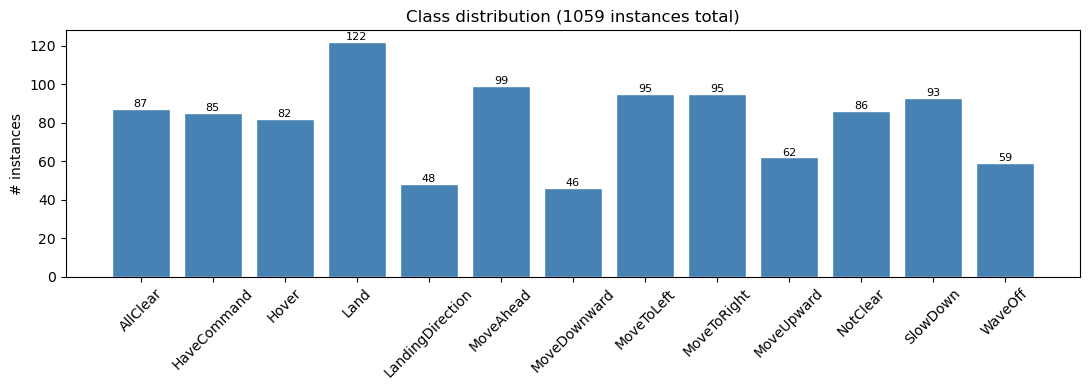

Most frequent class:  Land (122)
Least frequent class: MoveDownward (46)
Imbalance ratio (max/min): 2.65x


In [8]:
class_counts = Counter(labels)
counts_sorted = [class_counts[CLASS_TO_IDX[c]] for c in CLASS_NAMES]

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(CLASS_NAMES, counts_sorted, color='steelblue', edgecolor='white')
ax.set_ylabel('# instances')
ax.set_title(f'Class distribution ({len(labels)} instances total)')
ax.tick_params(axis='x', rotation=45)
for b, c in zip(bars, counts_sorted):
    ax.text(b.get_x() + b.get_width()/2, c + 1, str(c), ha='center', fontsize=8)
plt.tight_layout()
plt.show()

print(f'Most frequent class:  {CLASS_NAMES[np.argmax(counts_sorted)]} ({max(counts_sorted)})')
print(f'Least frequent class: {CLASS_NAMES[np.argmin(counts_sorted)]} ({min(counts_sorted)})')
print(f'Imbalance ratio (max/min): {max(counts_sorted)/min(counts_sorted):.2f}x')

**Observation.** The class ratio is 2.65 to 1. `Land` has 122 instances and
`MoveDownward` has 46. Accuracy can hide poor results on small classes. Macro-F1 is therefore the
main metric. Per class recall is also reported. This follows Week 2 Tutorial Question 7.


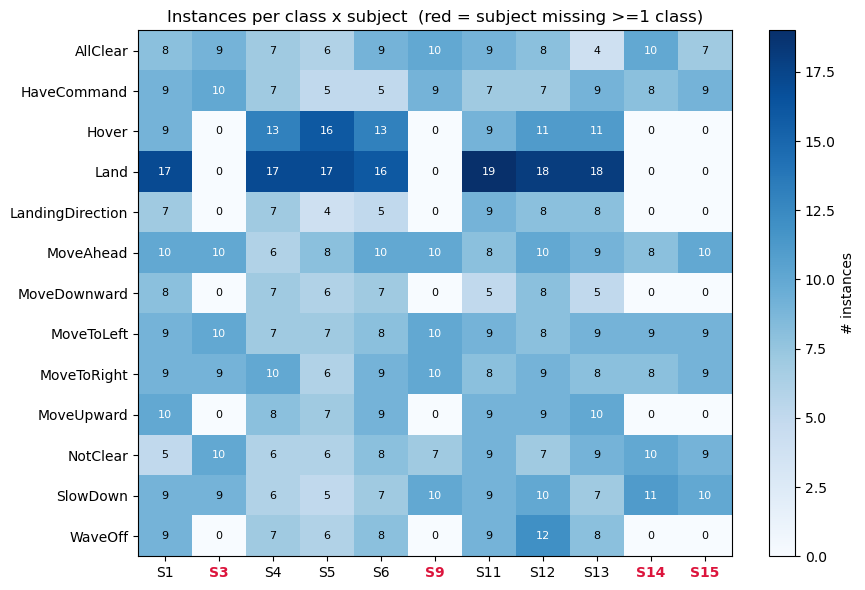

Full-coverage subjects (all 13 classes): [np.str_('S1'), np.str_('S4'), np.str_('S5'), np.str_('S6'), np.str_('S11'), np.str_('S12'), np.str_('S13')]
Partial-coverage subjects (missing classes): [np.str_('S3'), np.str_('S9'), np.str_('S14'), np.str_('S15')]
  S3 is missing: ['Hover', 'Land', 'LandingDirection', 'MoveDownward', 'MoveUpward', 'WaveOff']
  S9 is missing: ['Hover', 'Land', 'LandingDirection', 'MoveDownward', 'MoveUpward', 'WaveOff']
  S14 is missing: ['Hover', 'Land', 'LandingDirection', 'MoveDownward', 'MoveUpward', 'WaveOff']
  S15 is missing: ['Hover', 'Land', 'LandingDirection', 'MoveDownward', 'MoveUpward', 'WaveOff']


In [9]:
subject_ids = sorted(set(subjects), key=lambda s: int(s[1:]))
coverage = np.zeros((len(CLASS_NAMES), len(subject_ids)), dtype=int)
for cls_idx, cls in enumerate(CLASS_NAMES):
    for subj_idx, subj in enumerate(subject_ids):
        coverage[cls_idx, subj_idx] = int(np.sum((labels == cls_idx) & (subjects == subj)))

full_coverage_subjects = [s for i, s in enumerate(subject_ids) if np.all(coverage[:, i] > 0)]
partial_subjects = [s for s in subject_ids if s not in full_coverage_subjects]

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(coverage, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(subject_ids)))
ax.set_xticklabels(subject_ids)
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_yticklabels(CLASS_NAMES)
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        v = coverage[i, j]
        ax.text(j, i, str(v), ha='center', va='center',
                color='white' if v > coverage.max()/2 else 'black', fontsize=8)
# Flag the partial-coverage subjects on the x-axis in red.
for j, s in enumerate(subject_ids):
    if s in partial_subjects:
        ax.get_xticklabels()[j].set_color('crimson')
        ax.get_xticklabels()[j].set_fontweight('bold')
ax.set_title('Instances per class x subject  (red = subject missing >=1 class)')
plt.colorbar(im, ax=ax, label='# instances')
plt.tight_layout()
plt.show()

print('Full-coverage subjects (all 13 classes):', full_coverage_subjects)
print('Partial-coverage subjects (missing classes):', partial_subjects)
for s in partial_subjects:
    missing = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES)) if coverage[i, subject_ids.index(s)] == 0]
    print(f'  {s} is missing: {missing}')

**Observation.** Seven of the eleven subjects performed all 13 gestures. Subjects
S3, S9, S14, and S15 are missing the same six classes. These classes are `Hover`, `Land`,
`LandingDirection`, `MoveDownward`, `MoveUpward`, and `WaveOff`.

The validation folds must use subjects with all 13 classes. The four partial subjects still contain
valid training examples for seven classes. They are used for training only. Section 4 defines this
split. The split also keeps each subject in only one data partition. This follows the dependent data
principle in Week 2 Tutorial Question 8.


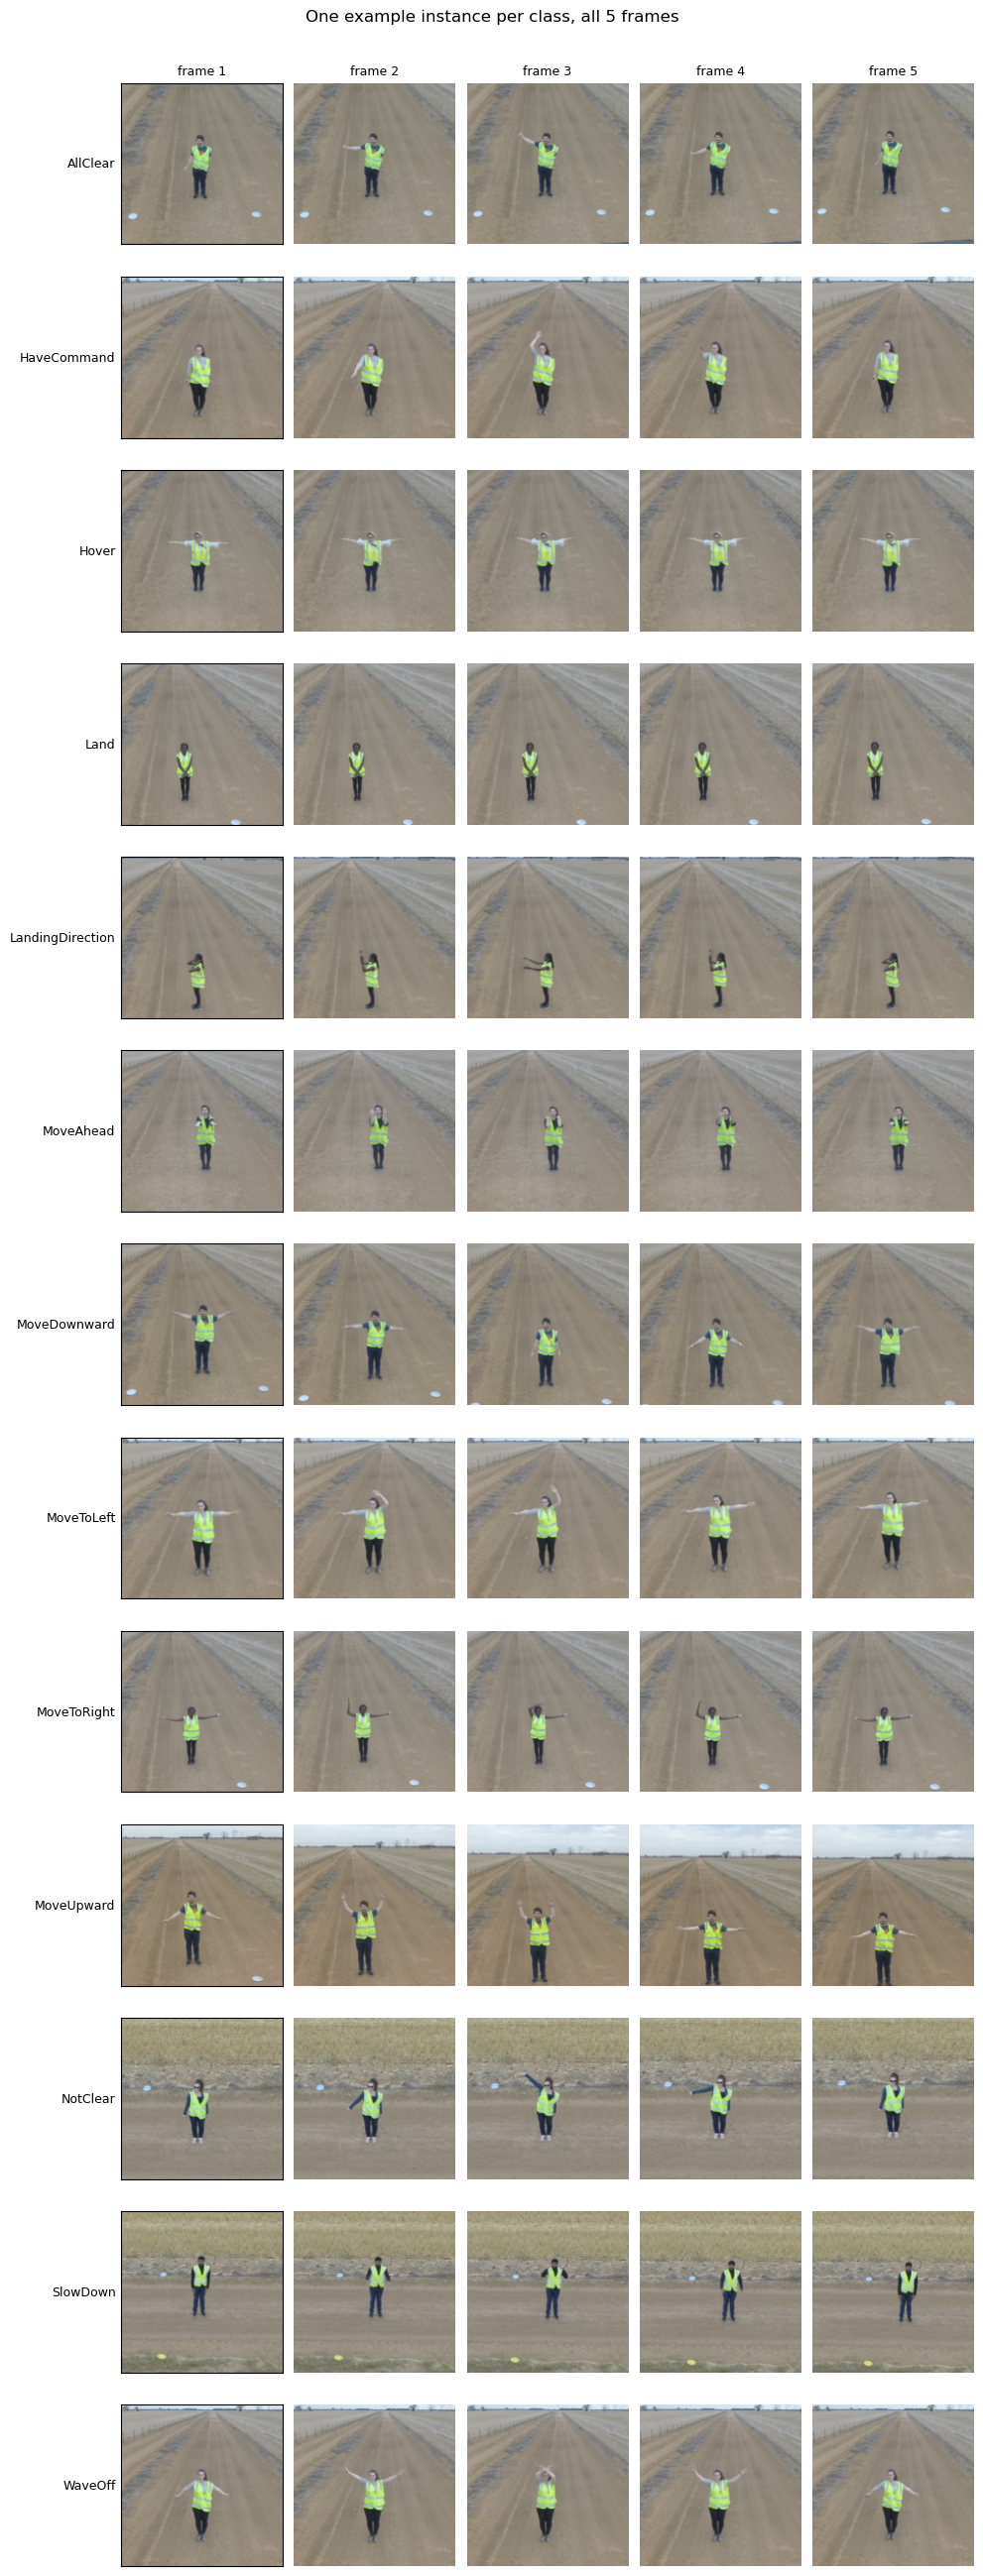

In [10]:
# What does the temporal information in an instance actually look like?
# Show all 5 frames for one example instance per class.
fig, axes = plt.subplots(NUM_CLASSES, N_FRAMES, figsize=(10, 2.0 * NUM_CLASSES))
rng = np.random.default_rng(SEED)
for row, cls in enumerate(CLASS_NAMES):
    idx = rng.choice(np.where(labels == CLASS_TO_IDX[cls])[0])
    for f in range(N_FRAMES):
        ax = axes[row, f]
        ax.imshow(frames_u8[idx, f])
        ax.axis('off')
        if f == 0:
            ax.set_ylabel(cls, rotation=0, ha='right', va='center', fontsize=9)
            ax.axis('on'); ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(f'frame {f+1}', fontsize=9)
plt.suptitle('One example instance per class, all 5 frames', y=1.001)
plt.tight_layout()
plt.show()

**Observation.** `MoveToLeft` and `MoveToRight` have similar poses. The same is
true for `MoveUpward` and `MoveDownward`, and for `AllClear` and `NotClear`.

Horizontal flipping may change the meaning of a directional gesture. Section 7 tests this effect.
The similar poses also suggest that one frame may be insufficient. Section 6 compares models that use
all five frames.


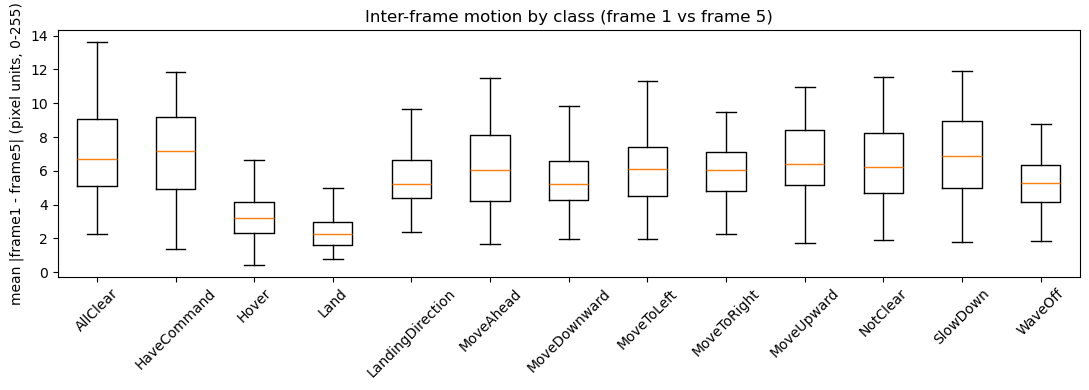

Least motion: ['Land', 'Hover', 'MoveDownward']
Most motion:  ['AllClear', 'SlowDown', 'HaveCommand']


In [11]:
# Quantify motion within an instance: mean absolute pixel difference between the
# first and last frame, per instance, grouped by class. If this is ~0 for every
# class, the whole premise of temporal fusion collapses -- worth checking directly
# rather than assuming motion is present.
frame1 = frames_u8[:, 0].astype(np.float32)
frame5 = frames_u8[:, -1].astype(np.float32)
motion = np.abs(frame1 - frame5).mean(axis=(1, 2, 3))  # (N,) mean abs diff per instance

by_class = [motion[labels == CLASS_TO_IDX[c]] for c in CLASS_NAMES]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(by_class, tick_labels=CLASS_NAMES, showfliers=False)
ax.set_ylabel('mean |frame1 - frame5| (pixel units, 0-255)')
ax.set_title('Inter-frame motion by class (frame 1 vs frame 5)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

order = np.argsort([np.median(m) for m in by_class])
print('Least motion:', [CLASS_NAMES[i] for i in order[:3]])
print('Most motion: ', [CLASS_NAMES[i] for i in order[-3:]])

**Observation.** Movement between frames is present in every class, but its size
varies. Static gestures have less movement. Directional gestures have more movement. This supports
the use of all five frames. Section 8 checks whether the final errors follow this pattern.


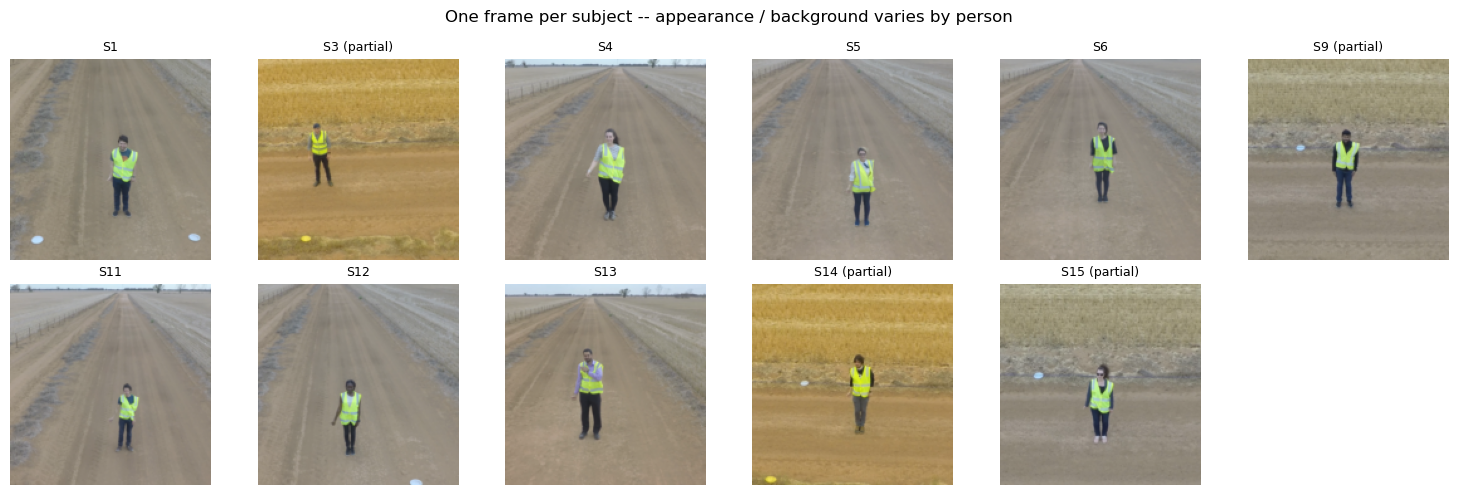

In [12]:
# Per-subject appearance variability -- different people, positions, lighting,
# backgrounds. This is the visual evidence behind the subject-disjoint-split
# decision: the demo-day receiver is someone the model has never seen, so
# "unseen subject" is the generalisation gap that actually matters.
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i, subj in enumerate(subject_ids):
    ax = axes.flat[i]
    idx = np.where(subjects == subj)[0][0]
    ax.imshow(frames_u8[idx, 0])
    tag = ' (partial)' if subj in partial_subjects else ''
    ax.set_title(subj + tag, fontsize=9)
    ax.axis('off')
for j in range(len(subject_ids), axes.size):
    axes.flat[j].axis('off')
plt.suptitle('One frame per subject -- appearance / background varies by person')
plt.tight_layout()
plt.show()

**Observation.** The subject is small in the original frame. At 160 by 160 pixels,
the subject is about 30 pixels tall and the arms are only a few pixels wide.

The background also varies with the recording group. Subjects S3, S9, S14, and S15 were recorded on
yellow stubble. The remaining subjects were recorded on a brown dirt road. A model may learn subject
or background features instead of the gesture. Section 4 therefore uses subject disjoint splits.
Sections 2 and 6 also test tighter crops.


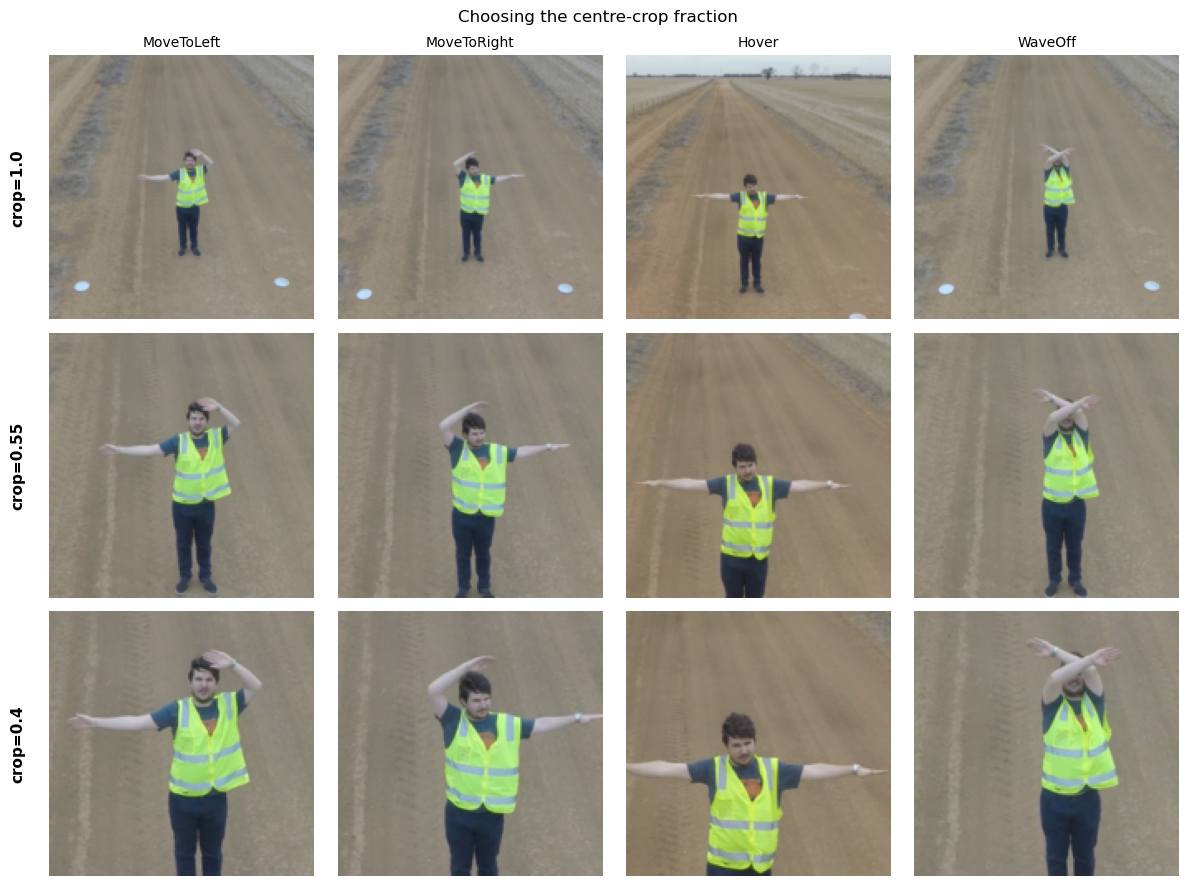

In [13]:
# How tight can the centre crop be? Too loose wastes the input budget on road;
# too tight clips the outstretched arms -- which are the whole signal for the
# direction classes. Checked visually rather than guessed.
crop_demo = [np.where(labels == CLASS_TO_IDX[c])[0][0]
             for c in ['MoveToLeft', 'MoveToRight', 'Hover', 'WaveOff']]
test_fracs = [1.0, 0.55, 0.40]
fig, axes = plt.subplots(len(test_fracs), len(crop_demo),
                          figsize=(3 * len(crop_demo), 3 * len(test_fracs)))
for r, fr in enumerate(test_fracs):
    for c, idx in enumerate(crop_demo):
        img = Image.open(instances[idx]['frame_paths'][2]).convert('RGB')
        W, H = img.size
        half = min(W, H) * fr / 2
        box = (int(W / 2 - half), int(H / 2 - half), int(W / 2 + half), int(H / 2 + half))
        ax = axes[r, c]
        ax.imshow(img.crop(box).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        ax.axis('off')
        if r == 0:
            ax.set_title(CLASS_NAMES[labels[idx]], fontsize=10)
        if c == 0:
            ax.text(-0.12, 0.5, f'crop={fr}', transform=ax.transAxes, rotation=90,
                    va='center', ha='center', fontsize=11, fontweight='bold')
plt.suptitle('Choosing the centre-crop fraction')
plt.tight_layout()
plt.show()

**Observation.** A full frame crop leaves the subject small. A crop fraction of
0.55 keeps the complete arm span and makes the gesture clearer. A crop fraction of 0.40 removes parts
of extended arms. The centre crop fraction is therefore set to 0.55.


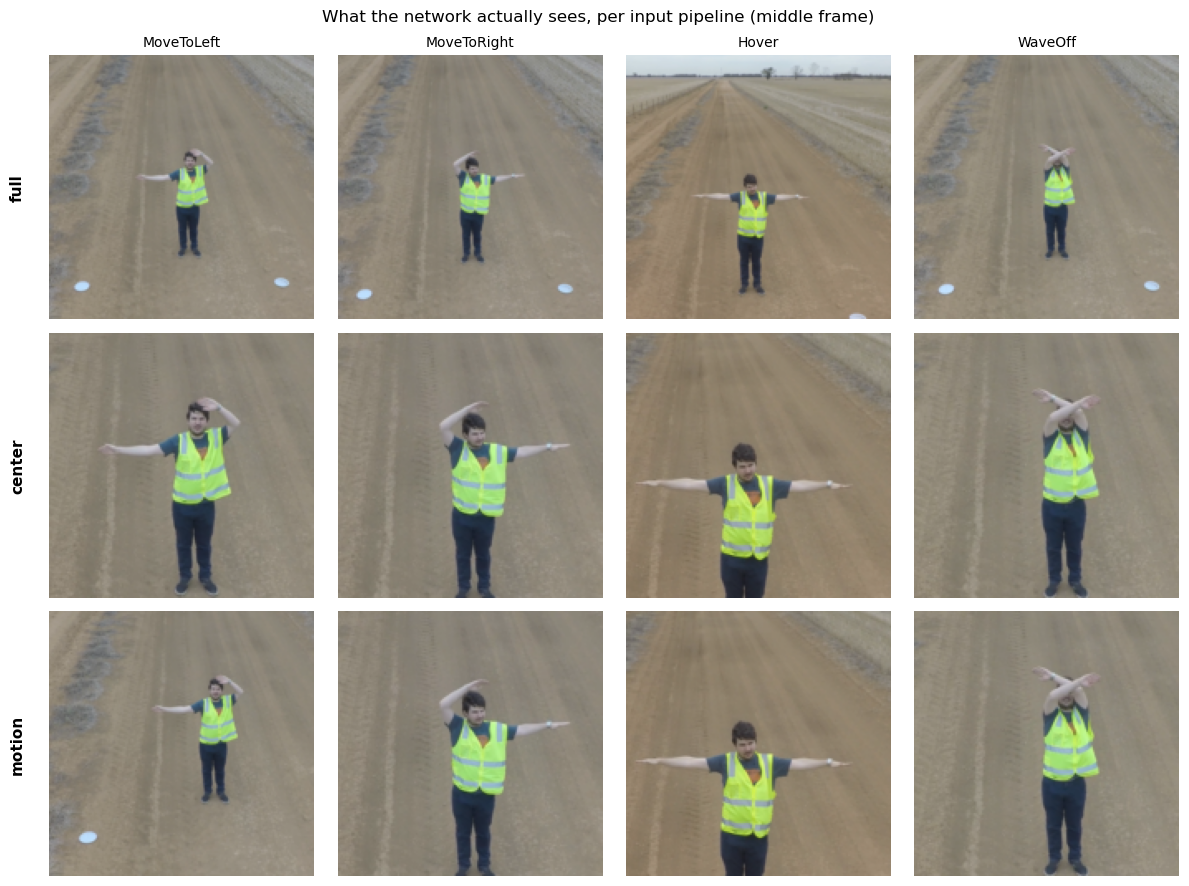

In [14]:
# Show what each of the three input pipelines actually feeds the network, so the
# choice in Section 6 is made on visible evidence rather than assertion.
demo_idx = [np.where(labels == CLASS_TO_IDX[c])[0][0]
            for c in ['MoveToLeft', 'MoveToRight', 'Hover', 'WaveOff']]
fig, axes = plt.subplots(len(PIPELINES), len(demo_idx), figsize=(3 * len(demo_idx), 3 * len(PIPELINES)))
for r, p in enumerate(PIPELINES):
    for c, idx in enumerate(demo_idx):
        ax = axes[r, c]
        ax.imshow(frames_by_pipeline[p][idx, 2])   # middle frame
        ax.axis('off')
        if r == 0:
            ax.set_title(CLASS_NAMES[labels[idx]], fontsize=10)
        if c == 0:
            ax.text(-0.12, 0.5, p, transform=ax.transAxes, rotation=90,
                    va='center', ha='center', fontsize=11, fontweight='bold')
plt.suptitle('What the network actually sees, per input pipeline (middle frame)')
plt.tight_layout()
plt.show()

**Observation.** Both crop methods enlarge the subject and remove much of the
background.

The motion proposal fails for 538 of 1,059 instances, or 50.8%. These instances use the centre crop.
Camera movement can affect the motion estimate. The motion crop is therefore not assumed to be
better. Section 6 compares all three pipelines.


---
## 3. Performance targets

The main metric is macro-F1. It gives equal weight to each class and is suitable for the class
imbalance found in Section 2. Per class recall is also reported.

A safety weighted error rate is used as a secondary metric. A missed `WaveOff` signal has a high
cost because it indicates an unsafe site. Confusion between `MoveToLeft` and `MoveToRight` also has a
high cost because it can send the aircraft in the wrong direction. These errors receive five times
the normal weight. Sections 8 and 9 report this metric.


In [15]:
SAFETY_WEIGHT = 5.0  # multiplier applied to the two error types above; magnitude is a judgement
                       # call (documented as such), not derived from data -- there is no accident
                       # log to calibrate it against.

def safety_weighted_error_rate(y_true, y_pred, class_names=CLASS_NAMES, weight=SAFETY_WEIGHT):
    """Fraction of instances misclassified, with WaveOff-missed and
    MoveToLeft<->MoveToRight confusions counted `weight` times."""
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    idx = {c: i for i, c in enumerate(class_names)}
    wrong = (y_true != y_pred).astype(float)
    is_waveoff_missed = (y_true == idx['WaveOff']) & (y_pred != idx['WaveOff'])
    is_lr_swap = ((y_true == idx['MoveToLeft']) & (y_pred == idx['MoveToRight'])) | \
                 ((y_true == idx['MoveToRight']) & (y_pred == idx['MoveToLeft']))
    weighted = np.where(is_waveoff_missed | is_lr_swap, weight, 1.0) * wrong
    return weighted.sum() / len(y_true)

In [16]:
# ---------------------------------------------------------------------------
# Trivial benchmarks -- the floor any real model must clear. No published
# benchmark exists for this dataset (it's the course's own gesture set), so
# rather than invent a literature number, the target value is set from these
# floors plus the single-frame baseline established in Section 5.
# ---------------------------------------------------------------------------
from sklearn.metrics import f1_score

y_true_all = labels
rng = np.random.default_rng(SEED)

random_pred = rng.integers(0, NUM_CLASSES, size=len(y_true_all))
majority_class = Counter(y_true_all).most_common(1)[0][0]
majority_pred = np.full_like(y_true_all, majority_class)

print(f'{"Benchmark":<20}{"Macro-F1":>10}{"Accuracy":>10}')
for name, pred in [('Random', random_pred), ('Majority class', majority_pred)]:
    f1 = f1_score(y_true_all, pred, average='macro', zero_division=0)
    acc = (pred == y_true_all).mean()
    print(f'{name:<20}{f1:>10.3f}{acc:>10.3f}')
print(f'\n(Majority class = "{CLASS_NAMES[majority_class]}", {Counter(y_true_all)[majority_class]} instances)')

Benchmark             Macro-F1  Accuracy
Random                   0.070     0.072
Majority class           0.016     0.115

(Majority class = "Land", 122 instances)


**Target value.**

The target is macro-F1 of at least 0.75 on subject disjoint validation. Each class should also have
recall of at least 0.50. The safety weighted error rate should not be dominated by missed `WaveOff`
signals or left and right confusion.

No published benchmark is available for this dataset. The value of 0.75 is a project target. It is
set before model development and is not changed after seeing the results.


In [17]:
# Bound to a name so every later plot and pass/fail check reads the target from
# one place rather than repeating the literal.
TARGET_VALUE = 0.75          # macro-F1, subject-disjoint
TARGET_MIN_CLASS_RECALL = 0.50
print(f'Target: macro-F1 >= {TARGET_VALUE} on subject-disjoint validation, '
      f'no class below {TARGET_MIN_CLASS_RECALL} recall.')

Target: macro-F1 >= 0.75 on subject-disjoint validation, no class below 0.5 recall.


---
## 4. Evaluation framework

The five frames from one gesture always remain together. Separating them would place almost identical
frames in training and validation.

The data split is also subject disjoint. The expected receiver is a person who is absent from the
training data. A random instance split would place the same person, clothing, and background in both
sets. It would measure an easier task. This follows Week 2 Tutorial Question 8.

The split uses the following groups.

- S12 and S13 form the locked test set. They have all 13 classes and the largest instance counts.
- The other nine subjects form the development set.
- Leave one subject out validation uses S1, S4, S5, S6, and S11 as the five validation subjects.
- S3, S9, S14, and S15 contain only seven classes. They are included in training but not validation.
- Results are reported as the mean and standard deviation across the five folds.

The test set is used once after model selection.


In [18]:
LOCKED_TEST_SUBJECTS = ['S12', 'S13']
LOSO_DEV_SUBJECTS = [s for s in full_coverage_subjects if s not in LOCKED_TEST_SUBJECTS]
TRAIN_ONLY_SUBJECTS = partial_subjects

assert set(LOCKED_TEST_SUBJECTS) <= set(full_coverage_subjects)
print('Locked test subjects (opened once, at the very end):', LOCKED_TEST_SUBJECTS)
print('LOSO dev subjects (5-fold CV for all model-selection decisions):', LOSO_DEV_SUBJECTS)
print('Train-only subjects (partial class coverage):', TRAIN_ONLY_SUBJECTS)

test_mask = np.isin(subjects, LOCKED_TEST_SUBJECTS)
dev_mask = ~test_mask
print(f'\n{test_mask.sum()} instances locked away for the final test.')
print(f'{dev_mask.sum()} instances available for development (LOSO CV + train-only subjects).')

Locked test subjects (opened once, at the very end): ['S12', 'S13']
LOSO dev subjects (5-fold CV for all model-selection decisions): [np.str_('S1'), np.str_('S4'), np.str_('S5'), np.str_('S6'), np.str_('S11')]
Train-only subjects (partial class coverage): [np.str_('S3'), np.str_('S9'), np.str_('S14'), np.str_('S15')]

240 instances locked away for the final test.
819 instances available for development (LOSO CV + train-only subjects).


In [19]:
def make_loso_folds(dev_subjects=LOSO_DEV_SUBJECTS, train_only=TRAIN_ONLY_SUBJECTS):
    """Yield (fold_name, train_mask, val_mask) for 5-fold leave-one-subject-out CV.
    Every fold's training set = all subjects except the held-out one and except the
    locked test subjects; every fold's validation set = exactly the held-out subject."""
    for held_out in dev_subjects:
        train_subjects = [s for s in dev_subjects if s != held_out] + train_only
        train_mask = np.isin(subjects, train_subjects)
        val_mask = (subjects == held_out)
        yield held_out, train_mask, val_mask

for held_out, tr, va in make_loso_folds():
    print(f'fold {held_out}: train={tr.sum():4d} instances, val={va.sum():4d} instances, '
          f'val classes present={len(set(labels[va]))}/{NUM_CLASSES}')

fold S1: train= 700 instances, val= 119 instances, val classes present=13/13
fold S4: train= 711 instances, val= 108 instances, val classes present=13/13
fold S5: train= 720 instances, val=  99 instances, val classes present=13/13
fold S6: train= 705 instances, val= 114 instances, val classes present=13/13
fold S11: train= 700 instances, val= 119 instances, val classes present=13/13


The following cell checks that subjects and instances do not overlap between the data partitions.


In [20]:
# No subject may appear on both sides of any fold, and the locked test subjects
# must never appear in any fold at all.
for held_out, tr, va in make_loso_folds():
    train_subjects_in_fold = set(subjects[tr])
    val_subjects_in_fold = set(subjects[va])
    assert train_subjects_in_fold.isdisjoint(val_subjects_in_fold), f'fold {held_out}: train/val subject overlap!'
    assert val_subjects_in_fold == {held_out}, f'fold {held_out}: unexpected val subjects {val_subjects_in_fold}'
    assert train_subjects_in_fold.isdisjoint(set(LOCKED_TEST_SUBJECTS)), f'fold {held_out}: test subject leaked into train!'
    assert val_subjects_in_fold.isdisjoint(set(LOCKED_TEST_SUBJECTS)), f'fold {held_out}: test subject leaked into val!'
print('All 5 LOSO folds are subject-disjoint and test subjects never appear during development. OK.')

All 5 LOSO folds are subject-disjoint and test subjects never appear during development. OK.


### Random split comparison

Section 6 also evaluates the selected architecture with a random 80% training and 20% validation
split. This split ignores subject identity. The difference between this result and the subject
disjoint result measures the effect of reusing subjects.


---
## 5. Baseline: single frame MobileNetV2

A leave one subject out training fold contains about 800 to 900 instances. This is small for training
a convolutional network from random weights. The Week 6 lecture also found that MobileNetV2 was data
limited on a larger dataset. ImageNet transfer learning is therefore used.

MobileNetV2 is used because the model must fit an embedded compute budget. It has about 2.2 million
backbone parameters. ResNet18 has about 11 million. MobileNetV2 is also used in the Week 6 lecture and
listed as a mobile architecture in Week 5 Lecture Part 1, slide 57.

Training has two stages. First, the new classifier is trained while the backbone is frozen. Next, the
upper backbone blocks are trained with a smaller learning rate. This follows Week 5 Lecture Part 2,
slides 13 to 17, and the Week 5 and Week 6 notebooks.


In [21]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def normalize(x):
    """x: (..., 3, H, W) float tensor in [0, 1] -> ImageNet-normalised.
    Broadcasts over any number of leading dims (single image, a 5-frame
    instance, or a batch of either), since IMAGENET_MEAN/STD are (3,1,1)."""
    mean = IMAGENET_MEAN.to(x.device, x.dtype)
    std = IMAGENET_STD.to(x.device, x.dtype)
    return (x - mean) / std


class MobileNetEncoder(nn.Module):
    """MobileNetV2 conv backbone + global average pooling -> one 1280-d embedding
    per frame. This is the Week 5 'bottleneck layer': the reusable, general-purpose
    feature extractor that everything else in this notebook is built on top of."""
    def __init__(self, pretrained=True):
        super().__init__()
        weights = MobileNet_V2_Weights.IMAGENET1K_V2 if pretrained else None
        self.features = mobilenet_v2(weights=weights).features
        self.out_dim = 1280
        self.n_blocks = len(self.features)

    def forward(self, x):                                    # x: (B, 3, H, W)
        f = self.features(x)                                 # (B, 1280, H', W')
        return F.adaptive_avg_pool2d(f, 1).flatten(1)         # GAP -> (B, 1280)

    def freeze(self):
        for p in self.features.parameters():
            p.requires_grad = False

    def unfreeze_from(self, block_idx):
        """Unfreeze features[block_idx:] only. Lower blocks keep the general,
        transferable ImageNet features frozen; upper blocks adapt to gestures."""
        for i, block in enumerate(self.features):
            for p in block.parameters():
                p.requires_grad = (i >= block_idx)

    def count_params(self):
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.parameters())
        print(f'  encoder trainable/total: {trainable:,} / {total:,} ({trainable/total*100:.1f}%)')


class SingleFrameClassifier(nn.Module):
    """Reference arm: one frame in, one class out. Used to (a) show what a
    single frame is worth before spending the temporal-fusion budget, and (b)
    as the per-frame model behind the majority-vote instance-level prediction."""
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        self.encoder = MobileNetEncoder(pretrained=pretrained)
        self.head = nn.Linear(self.encoder.out_dim, num_classes)

    def forward(self, x):                                     # x: (B, 3, H, W)
        return self.head(self.encoder(x))

In [22]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import torchvision.transforms.v2 as T2

class SingleFrameDataset(Dataset):
    """One (frame, label) example per *frame* -- 5x len(indices) examples per
    epoch. Every frame of an instance is trained as an independent example of
    that instance's class; at evaluation time predictions are majority-voted
    back up to one prediction per instance (see `predict_majority_vote` below).
    This mirrors the 'single-frame' baseline in Karpathy et al. 2014."""
    def __init__(self, indices, augment=None):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices) * N_FRAMES

    def __getitem__(self, k):
        inst = self.indices[k // N_FRAMES]
        frame = k % N_FRAMES
        img = torch.from_numpy(frames_u8[inst, frame]).permute(2, 0, 1).float() / 255.0
        if self.augment is not None:
            img = self.augment(img)
        return normalize(img), int(labels[inst])


class InstanceDataset(Dataset):
    """One (all 5 frames, label) example per *instance*. Used by every model
    that fuses across the whole instance (late fusion, early fusion) -- this is
    the 'one instance in, one class out' contract from the assignment spec.

    Augmentation note: `self.augment(imgs)` is called on the whole (5,3,H,W)
    stack at once, not per frame. torchvision.transforms.v2 samples its random
    parameters once per call and applies them to every image in the tensor it's
    given -- so this yields one consistent rotation/jitter draw shared by all 5
    frames of an instance, not 5 independently-randomised ones. That matters
    here specifically: Section 2 shows the frame-to-frame motion itself carries
    signal, and independently jittering each frame would add noise indistinguishable
    from that motion, undermining exactly the thing temporal fusion is meant to use."""
    def __init__(self, indices, augment=None):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        inst = self.indices[i]
        imgs = torch.from_numpy(frames_u8[inst]).permute(0, 3, 1, 2).float() / 255.0  # (5,3,H,W)
        if self.augment is not None:
            imgs = self.augment(imgs)          # one shared random draw applied to all 5 frames
        return normalize(imgs), int(labels[inst])

In [23]:
# ---------------------------------------------------------------------------
# Training loop -- directly descended from the Week 6 lecture notebook's
# run_epoch/train_and_track (cells 21-22), extended with macro-F1 (sklearn)
# in place of the binary-task metrics used there, since this is a 13-way
# problem. AMP is applied only where it actually pays off (device.type=='cuda',
# i.e. the AWS T4) -- see Section 0.
# ---------------------------------------------------------------------------
from sklearn.metrics import f1_score as _f1_score

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, all_y, all_pred = 0.0, [], []
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
                logits = model(xb)
                loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * yb.size(0)
            all_y.append(yb.detach().cpu())
            all_pred.append(logits.detach().argmax(1).cpu())
    y = torch.cat(all_y).numpy()
    pred = torch.cat(all_pred).numpy()
    return {
        'loss': total_loss / len(y),
        'macro_f1': _f1_score(y, pred, average='macro', zero_division=0),
        'accuracy': float((y == pred).mean()),
    }


def train_and_track(model, train_loader, val_loader, epochs, lr, optimizer=None, weight_decay=0.0,
                     verbose=True, name='model'):
    model = model.to(device)
    if optimizer is None:
        optimizer = torch.optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    hist = {k: [] for k in ['loss', 'macro_f1', 'accuracy', 'val_loss', 'val_macro_f1', 'val_accuracy']}
    for ep in range(epochs):
        tr = run_epoch(model, train_loader, criterion, optimizer)
        va = run_epoch(model, val_loader, criterion, optimizer=None)
        for k, v in tr.items():
            hist[k].append(v)
        for k, v in va.items():
            hist['val_' + k].append(v)
        if verbose:
            print(f'  [{name}] ep {ep+1:2d}/{epochs}  loss {tr["loss"]:.3f} f1 {tr["macro_f1"]:.3f}  |  '
                  f'val_loss {va["loss"]:.3f} val_f1 {va["macro_f1"]:.3f} val_acc {va["accuracy"]:.3f}')
    return hist


def plotter(histories, metric='loss', ylim=None):
    for name, hist in histories.items():
        epochs = range(1, len(hist[metric]) + 1)
        plt.plot(epochs, hist[metric], marker='o', markersize=3, label=f'{name} (train)')
        plt.plot(epochs, hist['val_' + metric], linestyle='--', marker='x', markersize=3, label=f'{name} (val)')
    plt.xlabel('epoch'); plt.ylabel(metric); plt.legend(fontsize=8); plt.grid(True, alpha=0.4)


@torch.no_grad()
def predict_majority_vote(model, indices):
    """Instance-level prediction from a per-frame model: run all 5 frames,
    argmax each, majority-vote to one label per instance. Puts the single-frame
    arm on the same instance-level footing as the fusion arms for comparison."""
    model.eval()
    y_true, y_pred = [], []
    for inst in indices:
        imgs = torch.from_numpy(frames_u8[inst]).permute(0, 3, 1, 2).float().to(device) / 255.0
        imgs = normalize(imgs)
        with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
            logits = model(imgs)                              # (5, num_classes)
        frame_preds = logits.argmax(1).cpu().numpy()
        vote = Counter(frame_preds).most_common(1)[0][0]
        y_true.append(int(labels[inst]))
        y_pred.append(vote)
    return np.array(y_true), np.array(y_pred)

### Training example on one fold

The next cells show the probe and fine tuning curves for one fold. All model comparisons in Sections
6 and 7 use the full five fold protocol.


In [24]:
DEMO_FOLD_SUBJECT, demo_train_mask, demo_val_mask = next(iter(make_loso_folds()))
demo_train_idx = np.where(demo_train_mask)[0]
demo_val_idx = np.where(demo_val_mask)[0]
print(f'Demo fold: holding out {DEMO_FOLD_SUBJECT}  '
      f'(train={len(demo_train_idx)} instances, val={len(demo_val_idx)} instances)')

demo_train_loader = DataLoader(SingleFrameDataset(demo_train_idx), batch_size=64, shuffle=True,
                                generator=g)
demo_val_loader = DataLoader(SingleFrameDataset(demo_val_idx), batch_size=128, shuffle=False)

set_seed()
baseline = SingleFrameClassifier().to(device)
baseline.encoder.freeze()
print('Step 1 -- linear probe (frozen backbone):')
baseline.encoder.count_params()

baseline_hist = {}
baseline_hist['probe'] = train_and_track(
    baseline, demo_train_loader, demo_val_loader, epochs=3, lr=1e-3, name='probe')

Demo fold: holding out S1  (train=700 instances, val=119 instances)
Step 1 -- linear probe (frozen backbone):
  encoder trainable/total: 0 / 2,223,872 (0.0%)
  [probe] ep  1/3  loss 2.146 f1 0.260  |  val_loss 2.405 val_f1 0.147 val_acc 0.224
  [probe] ep  2/3  loss 1.621 f1 0.521  |  val_loss 2.389 val_f1 0.122 val_acc 0.170
  [probe] ep  3/3  loss 1.347 f1 0.657  |  val_loss 2.473 val_f1 0.098 val_acc 0.139


Step 2 -- fine-tune (unfreeze top blocks, low LR):
  encoder trainable/total: 1,526,080 / 2,223,872 (68.6%)
  [fine-tune] ep  1/8  loss 0.992 f1 0.741  |  val_loss 2.468 val_f1 0.121 val_acc 0.168
  [fine-tune] ep  2/8  loss 0.627 f1 0.870  |  val_loss 2.620 val_f1 0.131 val_acc 0.168
  [fine-tune] ep  3/8  loss 0.431 f1 0.921  |  val_loss 2.739 val_f1 0.113 val_acc 0.138
  [fine-tune] ep  4/8  loss 0.293 f1 0.958  |  val_loss 2.877 val_f1 0.092 val_acc 0.116
  [fine-tune] ep  5/8  loss 0.210 f1 0.974  |  val_loss 2.921 val_f1 0.104 val_acc 0.128
  [fine-tune] ep  6/8  loss 0.148 f1 0.984  |  val_loss 3.062 val_f1 0.102 val_acc 0.129
  [fine-tune] ep  7/8  loss 0.106 f1 0.991  |  val_loss 3.173 val_f1 0.086 val_acc 0.118
  [fine-tune] ep  8/8  loss 0.080 f1 0.995  |  val_loss 3.285 val_f1 0.095 val_acc 0.123


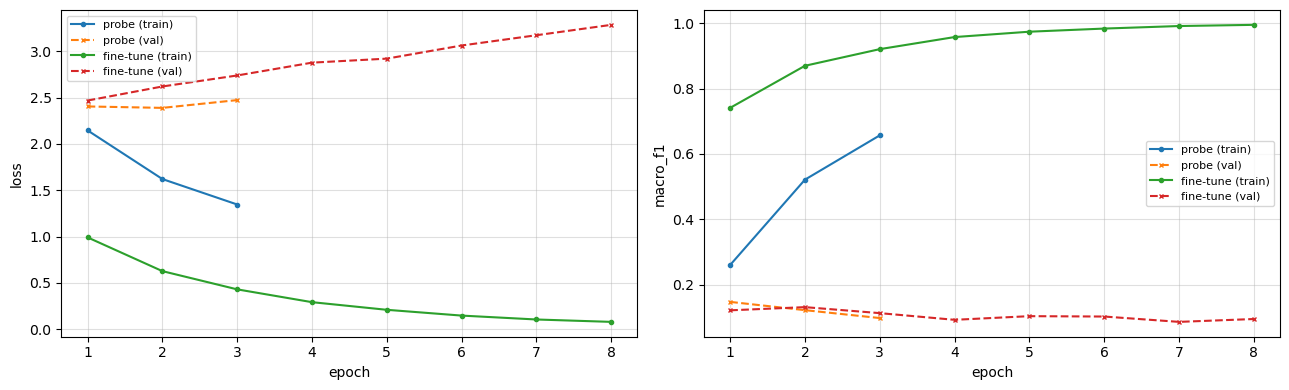

In [25]:
print('Step 2 -- fine-tune (unfreeze top blocks, low LR):')
baseline.encoder.unfreeze_from(baseline.encoder.n_blocks - 4)   # top 4 of 19 inverted-residual blocks
baseline.encoder.count_params()

baseline_hist['fine-tune'] = train_and_track(
    baseline, demo_train_loader, demo_val_loader, epochs=8, lr=1e-4, name='fine-tune')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plt.sca(axes[0]); plotter(baseline_hist, 'loss')
plt.sca(axes[1]); plotter(baseline_hist, 'macro_f1', ylim=(0, 1))
plt.tight_layout(); plt.show()

In [26]:
y_true, y_pred = predict_majority_vote(baseline, demo_val_idx)
baseline_instance_f1 = _f1_score(y_true, y_pred, average='macro', zero_division=0)
print(f'Single-frame baseline, instance-level macro-F1 (majority vote, held-out {DEMO_FOLD_SUBJECT}): '
      f'{baseline_instance_f1:.3f}')

Single-frame baseline, instance-level macro-F1 (majority vote, held-out S1): 0.066


**Baseline result.** The model overfits the training subjects.

Training macro-F1 increases from 0.260 to 0.657 during the probe. It then increases from 0.741 to
0.995 during fine tuning. Validation macro-F1 decreases from 0.147 to 0.095. Validation loss also
increases from 2.41 to 3.29. Fine tuning therefore reduces validation performance.

The instance level macro-F1 on held out S1 is 0.066. The random prediction reference is 0.070.

The target remains 0.75 because it was fixed before training. The result also indicates that the
full image contains weak gesture information after resizing. Section 6 tests crops before comparing
the final architectures.


---
## 6. Using all five frames

Three architectures are compared on the same folds.

1. The single frame model is the baseline. It does not satisfy the requirement to use all frames.
2. Late fusion applies one shared MobileNetV2 encoder to each frame. The five embeddings are combined
   by the `TemporalFusionHead`.
3. Early fusion stacks the five RGB frames into 15 channels. The first MobileNetV2 convolution is
   changed to accept these channels.

Two other methods were considered. A two stream network would require optical flow and a second
convolutional network. A motion history image would combine the sequence into one image and remove
frame order information. These methods were not selected because they add compute or remove temporal
detail.

Late fusion and early fusion are described in Karpathy et al., *Large-scale Video Classification with
Convolutional Neural Networks*, CVPR 2014. Both methods use only 2-D convolution.


In [27]:
class TemporalFusionHead(nn.Module):
    """*** Self-built segment. *** Takes per-frame 1280-d MobileNetV2 embeddings
    for all 5 frames of one instance and produces 13 class logits. Three tuned
    hyperparameters: bottleneck width, dropout, and how the 5 frame embeddings
    are combined into one.

    bottleneck : Linear + ReLU + Dropout channel reduction before the
                 classifier -- the 1x1-bottleneck idea from Week 5 slides 36-37,
                 here reducing the *feature* dimension rather than conv channels.
    aggregate  : combine the 5 (now bottlenecked) frame embeddings into one.
                 'mean'/'max' are the Week 5 global-average/max-pooling idea
                 (slides 40-41, 44) applied along the temporal axis instead of
                 the spatial one. 'learned' is a single softmax-normalised
                 weight per frame *position* (0..4), shared across the batch and
                 across classes -- a fixed positional weighting, not attention
                 over frame content, so it stays outside the assignment's ban
                 on temporal attention.
    """
    def __init__(self, in_dim=1280, bottleneck_dim=256, dropout=0.2,
                 num_classes=NUM_CLASSES, aggregate='mean'):
        super().__init__()
        self.bottleneck = nn.Sequential(
            nn.Linear(in_dim, bottleneck_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )
        self.aggregate = aggregate
        if aggregate == 'learned':
            self.frame_weights = nn.Parameter(torch.zeros(N_FRAMES))
        self.classifier = nn.Linear(bottleneck_dim, num_classes)

    def forward(self, feats):                                    # feats: (B, 5, in_dim)
        b = self.bottleneck(feats)                                # (B, 5, bottleneck_dim)
        if self.aggregate == 'mean':
            pooled = b.mean(dim=1)
        elif self.aggregate == 'max':
            pooled = b.max(dim=1).values
        elif self.aggregate == 'learned':
            w = torch.softmax(self.frame_weights, dim=0)          # (5,)
            pooled = (b * w.view(1, N_FRAMES, 1)).sum(dim=1)
        else:
            raise ValueError(self.aggregate)
        return self.classifier(pooled)


class LateFusionClassifier(nn.Module):
    """End-to-end version: shared MobileNetV2 encoder + TemporalFusionHead.
    Used in Stage B once the head design is chosen in Stage A below."""
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True, **head_kwargs):
        super().__init__()
        self.encoder = MobileNetEncoder(pretrained=pretrained)
        self.head = TemporalFusionHead(in_dim=self.encoder.out_dim, num_classes=num_classes, **head_kwargs)

    def forward(self, x):                                         # x: (B, 5, 3, H, W)
        B, Tn, C, H, W = x.shape
        feats = self.encoder(x.reshape(B * Tn, C, H, W))           # one shared-weight pass, all frames at once
        return self.head(feats.view(B, Tn, -1))


class EarlyFusionClassifier(nn.Module):
    """Stack the 5 frames on the channel axis (15ch) and widen MobileNetV2's
    first conv to match, tiling the pretrained 3-channel kernel /5 so the
    ImageNet initialisation is preserved (Week 4/5 conv arithmetic; Week 5
    tutorial Q3) instead of starting that one layer from random weights."""
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        weights = MobileNet_V2_Weights.IMAGENET1K_V2 if pretrained else None
        base = mobilenet_v2(weights=weights)
        old_conv = base.features[0][0]                             # Conv2d(3, 32, k=3, s=2, p=1, bias=False)
        new_conv = nn.Conv2d(3 * N_FRAMES, old_conv.out_channels, kernel_size=old_conv.kernel_size,
                              stride=old_conv.stride, padding=old_conv.padding, bias=False)
        with torch.no_grad():
            new_conv.weight.copy_(old_conv.weight.repeat(1, N_FRAMES, 1, 1) / N_FRAMES)
        base.features[0][0] = new_conv
        self.features = base.features
        self.head = nn.Linear(1280, num_classes)

    def forward(self, x):                                          # x: (B, 5, 3, H, W)
        B = x.shape[0]
        x = x.reshape(B, 3 * N_FRAMES, IMG_SIZE, IMG_SIZE)
        f = F.adaptive_avg_pool2d(self.features(x), 1).flatten(1)
        return self.head(f)

### Stage A: frozen feature comparison

The backbone is first frozen and used to extract an embedding for each frame. The embeddings are
cached. This allows each option to be compared across five folds without repeating full backbone
training.

The comparisons are completed in this order.

1. Compare the `full`, `center`, and `motion` input pipelines.
2. Compare single frame, early fusion, and late fusion on the selected pipeline.
3. Tune aggregation, hidden width, and dropout in the fusion head.

No augmentation is used in this stage because it cannot be applied after feature extraction.
Augmentation is tested during end to end training in Section 7.


In [28]:
def mean_std(arr):
    return f'{arr.mean():.3f} +/- {arr.std():.3f}'

frozen_encoder = MobileNetEncoder(pretrained=True)
frozen_encoder.freeze()

@torch.no_grad()
def extract_late_features(encoder, frames, batch_size=256):
    """One embedding per frame from the frozen shared encoder. Returns (N, 5, 1280)."""
    encoder.eval().to(device)
    N = len(frames)
    flat = frames.reshape(N * N_FRAMES, IMG_SIZE, IMG_SIZE, 3)
    out = []
    for start in range(0, len(flat), batch_size):
        chunk = flat[start:start + batch_size]
        x = normalize(torch.from_numpy(chunk).permute(0, 3, 1, 2).float().to(device) / 255.0)
        with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
            f = encoder(x)
        out.append(f.float().cpu())
    return torch.cat(out).numpy().reshape(N, N_FRAMES, -1)

with section('Stage A: frozen feature extraction (all 3 input pipelines)'):
    late_features_by_pipeline = {}
    for p in PIPELINES:
        cache_p = CACHE_DIR / f'late_features_{p}.npy'
        if cache_p.exists():
            late_features_by_pipeline[p] = np.load(cache_p)
        else:
            late_features_by_pipeline[p] = extract_late_features(frozen_encoder, frames_by_pipeline[p])
            np.save(cache_p, late_features_by_pipeline[p])
        print(f'  {p:7s} late_features: {late_features_by_pipeline[p].shape}')

--- Stage A: frozen feature extraction (all 3 input pipelines) ---
  full    late_features: (1059, 5, 1280)
  center  late_features: (1059, 5, 1280)
  motion  late_features: (1059, 5, 1280)
[Stage A: frozen feature extraction (all 3 input pipelines) finished in 0.3 min]


In [29]:
class FeatureArrayDataset(Dataset):
    """Wraps a precomputed feature array (any shape (N, ...)) + integer labels."""
    def __init__(self, x, y):
        self.x = torch.from_numpy(x).float()
        self.y = torch.from_numpy(np.asarray(y)).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


def frame_level_xy(indices, feats):
    """(len(indices)*5, D) frame-level rows + repeated labels, for training a
    per-frame model whose evaluation is majority-voted back to instance level."""
    idx = np.asarray(indices)
    x = feats[idx].reshape(-1, feats.shape[-1])
    y = np.repeat(labels[idx], N_FRAMES)
    return x, y


@torch.no_grad()
def predict_majority_vote_from_features(model, indices, feats):
    model.eval()
    idx = np.asarray(indices)
    x = torch.from_numpy(feats[idx].reshape(-1, feats.shape[-1])).float().to(device)
    logits = model(x)
    frame_preds = logits.argmax(1).cpu().numpy().reshape(len(idx), N_FRAMES)
    votes = np.array([Counter(row).most_common(1)[0][0] for row in frame_preds])
    return labels[idx], votes


def run_loso_stageA(build_model_fn, feats, mode='instance', epochs=15, lr=1e-3, folds=None, verbose=False):
    """Train + evaluate build_model_fn() on every LOSO fold using precomputed
    frozen features.
    mode='instance': model consumes one instance's features directly
                      ((5,1280) for late fusion, (1280,) for early fusion).
    mode='frame':     model consumes one frame's features; evaluated by
                      majority vote across the instance's 5 frames (single-frame arm)."""
    folds = folds if folds is not None else list(make_loso_folds())
    fold_f1s = []
    for held_out, train_mask, val_mask in folds:
        train_idx, val_idx = np.where(train_mask)[0], np.where(val_mask)[0]
        set_seed()
        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()

        if mode == 'instance':
            x_tr, y_tr = feats[train_idx], labels[train_idx]
            train_loader = DataLoader(FeatureArrayDataset(x_tr, y_tr), batch_size=64, shuffle=True, generator=g)
            for _ in range(epochs):
                run_epoch(model, train_loader, criterion, optimizer)
            x_va, y_va = feats[val_idx], labels[val_idx]
            val_loader = DataLoader(FeatureArrayDataset(x_va, y_va), batch_size=128, shuffle=False)
            f1 = run_epoch(model, val_loader, criterion, optimizer=None)['macro_f1']
        else:
            x_tr, y_tr = frame_level_xy(train_idx, feats)
            train_loader = DataLoader(FeatureArrayDataset(x_tr, y_tr), batch_size=128, shuffle=True, generator=g)
            for _ in range(epochs):
                run_epoch(model, train_loader, criterion, optimizer)
            y_true, y_pred = predict_majority_vote_from_features(model, val_idx, feats)
            f1 = _f1_score(y_true, y_pred, average='macro', zero_division=0)

        fold_f1s.append(f1)
        if verbose:
            print(f'    fold {held_out}: macro-F1={f1:.3f}')
    return np.array(fold_f1s)

#### Input pipeline

The three input pipelines use the same head, folds, and training settings.


In [30]:
with section('Stage A: input pipeline comparison (full vs center vs motion)'):
    pipeline_f1 = {}
    for p in PIPELINES:
        f1s = run_loso_stageA(lambda: TemporalFusionHead(),
                               late_features_by_pipeline[p], mode='instance')
        pipeline_f1[p] = f1s
        print(f'  {p:7s} -> {mean_std(f1s)}')

    BEST_PIPELINE = max(pipeline_f1, key=lambda k: pipeline_f1[k].mean())
    print(f'\nBest input pipeline: {BEST_PIPELINE}')

--- Stage A: input pipeline comparison (full vs center vs motion) ---
  full    -> 0.234 +/- 0.036
  center  -> 0.396 +/- 0.076
  motion  -> 0.412 +/- 0.063

Best input pipeline: motion
[Stage A: input pipeline comparison (full vs center vs motion) finished in 0.1 min]


ACTIVE_PIPELINE = 'motion'; frames_u8 (1059, 5, 160, 160, 3)


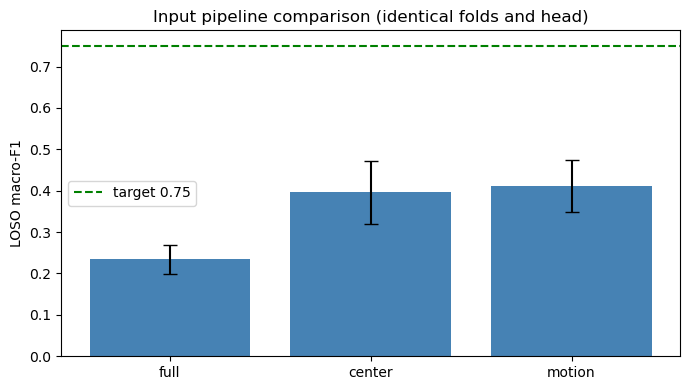

In [31]:
# Lock the winning pipeline in as the active one for EVERYTHING downstream --
# the end-to-end training in Sections 7 and 9, the error analysis in Section 8,
# and the webcam clips in Section 9 all use this from here on.
ACTIVE_PIPELINE = BEST_PIPELINE
frames_u8 = frames_by_pipeline[ACTIVE_PIPELINE]
late_features = late_features_by_pipeline[ACTIVE_PIPELINE]
print(f'ACTIVE_PIPELINE = {ACTIVE_PIPELINE!r}; frames_u8 {frames_u8.shape}')

fig, ax = plt.subplots(figsize=(7, 4))
names = list(PIPELINES)
ax.bar(names, [pipeline_f1[p].mean() for p in names],
       yerr=[pipeline_f1[p].std() for p in names], capsize=5, color='steelblue')
ax.axhline(TARGET_VALUE, ls='--', c='green', label=f'target {TARGET_VALUE}')
ax.set_ylabel('LOSO macro-F1'); ax.set_title('Input pipeline comparison (identical folds and head)')
ax.legend(); plt.tight_layout(); plt.show()

**Input pipeline result.** The `motion` pipeline has the highest mean macro-F1.

| Pipeline | LOSO macro-F1 |
|---|---|
| `full` | 0.234 ± 0.036 |
| `center` | 0.396 ± 0.076 |
| **`motion`** | **0.412 ± 0.063** |

The `motion` crop improves macro-F1 by 0.178 compared with the full frame. This is the largest gain
in the notebook. It supports the observation that the full image contains distracting subject and
background information.

The difference between `motion` and `center` is 0.016. This is smaller than the variation between
folds. The two crop methods therefore have similar measured performance. The motion pipeline is used
for the remaining experiments because it has the highest mean. A centre crop would be simpler for
deployment.


In [32]:
EARLY_FEATURE_CACHE = CACHE_DIR / f'early_features_{ACTIVE_PIPELINE}.npy'

with section('Stage A: early-fusion feature extraction (winning pipeline)'):
    frozen_early = EarlyFusionClassifier(pretrained=True)
    for p_ in frozen_early.parameters():
        p_.requires_grad = False

    if EARLY_FEATURE_CACHE.exists():
        early_features = np.load(EARLY_FEATURE_CACHE)
    else:
        @torch.no_grad()
        def extract_early_features(model, batch_size=128):
            """One embedding per instance from the frozen early-fusion (15ch) backbone. Returns (N, 1280)."""
            model.eval().to(device)
            N = len(labels)
            out = []
            for start in range(0, N, batch_size):
                idx = np.arange(start, min(start + batch_size, N))
                imgs = torch.from_numpy(frames_u8[idx]).permute(0, 1, 4, 2, 3).float().to(device) / 255.0
                imgs = normalize(imgs)
                b = imgs.shape[0]
                x = imgs.reshape(b, 3 * N_FRAMES, IMG_SIZE, IMG_SIZE)
                with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
                    f = F.adaptive_avg_pool2d(model.features(x), 1).flatten(1)
                out.append(f.float().cpu())
            return torch.cat(out).numpy()

        early_features = extract_early_features(frozen_early)
        np.save(EARLY_FEATURE_CACHE, early_features)
    print('early_features:', early_features.shape)

--- Stage A: early-fusion feature extraction (winning pipeline) ---
early_features: (1059, 1280)
[Stage A: early-fusion feature extraction (winning pipeline) finished in 0.1 min]


In [33]:
with section('Stage A: single-frame vs early-fusion vs late-fusion (frozen backbone)'):
    print('Single-frame (frozen features, majority vote):')
    f1_single = run_loso_stageA(lambda: nn.Linear(1280, NUM_CLASSES), late_features, mode='frame', verbose=True)
    print('  ->', mean_std(f1_single))

    print('\nEarly fusion (frozen backbone, linear head):')
    f1_early = run_loso_stageA(lambda: nn.Linear(1280, NUM_CLASSES), early_features, mode='instance', verbose=True)
    print('  ->', mean_std(f1_early))

    print('\nLate fusion (frozen backbone, default TemporalFusionHead):')
    f1_late_default = run_loso_stageA(lambda: TemporalFusionHead(), late_features, mode='instance', verbose=True)
    print('  ->', mean_std(f1_late_default))

--- Stage A: single-frame vs early-fusion vs late-fusion (frozen backbone) ---
Single-frame (frozen features, majority vote):
    fold S1: macro-F1=0.379
    fold S4: macro-F1=0.219
    fold S5: macro-F1=0.251
    fold S6: macro-F1=0.287
    fold S11: macro-F1=0.419
  -> 0.311 +/- 0.076

Early fusion (frozen backbone, linear head):
    fold S1: macro-F1=0.433
    fold S4: macro-F1=0.358
    fold S5: macro-F1=0.362
    fold S6: macro-F1=0.384
    fold S11: macro-F1=0.353
  -> 0.378 +/- 0.030

Late fusion (frozen backbone, default TemporalFusionHead):
    fold S1: macro-F1=0.524
    fold S4: macro-F1=0.406
    fold S5: macro-F1=0.263
    fold S6: macro-F1=0.327
    fold S11: macro-F1=0.524
  -> 0.408 +/- 0.104
[Stage A: single-frame vs early-fusion vs late-fusion (frozen backbone) finished in 0.1 min]


### Head tuning

The head parameters are tuned one at a time. Aggregation is selected first. Hidden width is selected
next. Dropout is selected last. This produces nine runs instead of a full 27 setting grid.


In [34]:
with section('TemporalFusionHead sweep: aggregation'):
    agg_results = {}
    for agg in ['mean', 'max', 'learned']:
        f1s = run_loso_stageA(lambda agg=agg: TemporalFusionHead(aggregate=agg), late_features)
        agg_results[agg] = f1s
        print(f'  aggregate={agg:8s} -> {mean_std(f1s)}')
    best_agg = max(agg_results, key=lambda k: agg_results[k].mean())
    print('Best aggregation:', best_agg)

--- TemporalFusionHead sweep: aggregation ---
  aggregate=mean     -> 0.403 +/- 0.069
  aggregate=max      -> 0.523 +/- 0.059
  aggregate=learned  -> 0.412 +/- 0.062
Best aggregation: max
[TemporalFusionHead sweep: aggregation finished in 0.1 min]


In [35]:
with section('TemporalFusionHead sweep: bottleneck width'):
    width_results = {}
    for width in [128, 256, 512]:
        f1s = run_loso_stageA(lambda w=width: TemporalFusionHead(aggregate=best_agg, bottleneck_dim=w), late_features)
        width_results[width] = f1s
        print(f'  width={width:4d} -> {mean_std(f1s)}')
    best_width = max(width_results, key=lambda k: width_results[k].mean())
    print('Best width:', best_width)

--- TemporalFusionHead sweep: bottleneck width ---
  width= 128 -> 0.472 +/- 0.069
  width= 256 -> 0.526 +/- 0.046
  width= 512 -> 0.516 +/- 0.045
Best width: 256
[TemporalFusionHead sweep: bottleneck width finished in 0.1 min]


In [36]:
with section('TemporalFusionHead sweep: dropout'):
    drop_results = {}
    for p in [0.0, 0.2, 0.4]:
        f1s = run_loso_stageA(
            lambda p=p: TemporalFusionHead(aggregate=best_agg, bottleneck_dim=best_width, dropout=p),
            late_features)
        drop_results[p] = f1s
        print(f'  dropout={p:.1f} -> {mean_std(f1s)}')
    best_dropout = max(drop_results, key=lambda k: drop_results[k].mean())
    print('Best dropout:', best_dropout)

f1_late_tuned = drop_results[best_dropout]

def build_late():
    """The chosen architecture with its tuned head hyperparameters -- built
    fresh (untrained, ImageNet-initialised backbone) each time this is called,
    since every fold/config below needs its own independently-trained copy."""
    return LateFusionClassifier(aggregate=best_agg, bottleneck_dim=best_width, dropout=best_dropout)

--- TemporalFusionHead sweep: dropout ---
  dropout=0.0 -> 0.534 +/- 0.051
  dropout=0.2 -> 0.524 +/- 0.055
  dropout=0.4 -> 0.506 +/- 0.048
Best dropout: 0.0
[TemporalFusionHead sweep: dropout finished in 0.1 min]


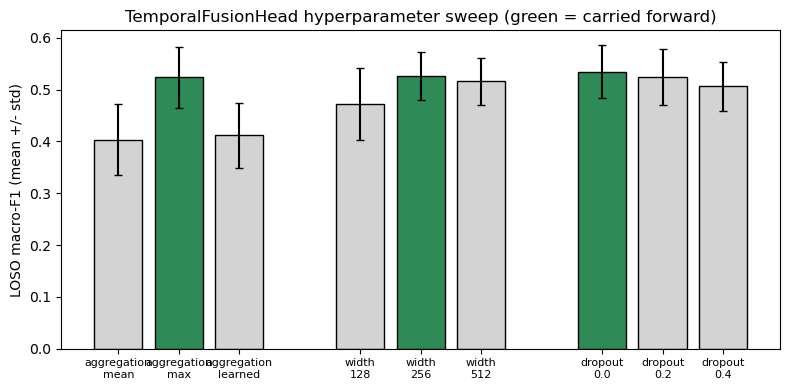

In [37]:
fig, ax = plt.subplots(figsize=(8, 4))
sweeps = [('aggregation', agg_results, best_agg), ('width', width_results, best_width),
          ('dropout', drop_results, best_dropout)]
xpos = 0
xticks, xlabels = [], []
for sweep_name, results, winner in sweeps:
    for k, v in results.items():
        color = 'seagreen' if k == winner else 'lightgray'
        ax.bar(xpos, v.mean(), yerr=v.std(), color=color, edgecolor='black', capsize=3)
        xticks.append(xpos); xlabels.append(f'{sweep_name}\n{k}')
        xpos += 1
    xpos += 1
ax.set_xticks(xticks); ax.set_xticklabels(xlabels, fontsize=8)
ax.set_ylabel('LOSO macro-F1 (mean +/- std)')
ax.set_title('TemporalFusionHead hyperparameter sweep (green = carried forward)')
plt.tight_layout(); plt.show()

### Stage A summary


In [38]:
print(f'{"Arm":<40}{"LOSO macro-F1":>20}')
print('=' * 60)
print(f'{"Single-frame (majority vote)":<40}{mean_std(f1_single):>20}')
print(f'{"Early fusion (frozen)":<40}{mean_std(f1_early):>20}')
print(f'{"Late fusion, default head (frozen)":<40}{mean_std(f1_late_default):>20}')
print(f'{"Late fusion, tuned head (frozen)":<40}{mean_std(f1_late_tuned):>20}')

Arm                                            LOSO macro-F1
Single-frame (majority vote)                 0.311 +/- 0.076
Early fusion (frozen)                        0.378 +/- 0.030
Late fusion, default head (frozen)           0.408 +/- 0.104
Late fusion, tuned head (frozen)             0.534 +/- 0.051


**Architecture result.** Late fusion has the highest mean macro-F1.

| Model | LOSO macro-F1 |
|---|---|
| Single frame with majority vote | 0.311 ± 0.076 |
| Early fusion with frozen backbone | 0.378 ± 0.030 |
| Late fusion with default head | 0.408 ± 0.104 |
| **Late fusion with tuned head** | **0.534 ± 0.051** |

Late fusion improves macro-F1 by about 0.10 compared with the single frame result. The difference
between the default late fusion and early fusion models is 0.030. This is within the fold variation.
Late fusion is selected because it keeps the pretrained three channel input layer unchanged.

The head tuning improves macro-F1 from 0.408 to 0.534.

- Maximum aggregation scores 0.523. Mean aggregation scores 0.403. Learned positional aggregation
  scores 0.412. Maximum aggregation may retain the frame with the largest arm extension.
- A hidden width of 256 scores 0.526. Widths of 512 and 128 score 0.516 and 0.472.
- Dropout of 0.0 scores 0.534. Dropout of 0.2 scores 0.524. Dropout of 0.4 scores 0.506.

The selected model uses late fusion, maximum aggregation, a hidden width of 256, and no dropout.

### Constraint check

The following cell verifies that the model contains no recurrent layer, 3-D convolution, or temporal
attention.


In [39]:
FORBIDDEN_MODULE_TYPES = (
    nn.RNN, nn.LSTM, nn.GRU, nn.RNNCell, nn.LSTMCell, nn.GRUCell,
    nn.Conv3d, nn.ConvTranspose3d,
    nn.MultiheadAttention, nn.TransformerEncoder, nn.TransformerDecoder, nn.TransformerEncoderLayer,
)

def assert_2d_conv_only(model, name):
    hits = [(n, type(m).__name__) for n, m in model.named_modules() if isinstance(m, FORBIDDEN_MODULE_TYPES)]
    assert not hits, f'{name} contains forbidden module(s): {hits}'
    n_conv2d = sum(1 for m in model.modules() if isinstance(m, nn.Conv2d))
    print(f'{name}: OK -- no recurrent / 3-D-conv / attention modules; {n_conv2d} Conv2d layers.')

assert_2d_conv_only(build_late(), 'LateFusionClassifier (chosen architecture)')
assert_2d_conv_only(EarlyFusionClassifier(pretrained=False), 'EarlyFusionClassifier (alternative considered)')

LateFusionClassifier (chosen architecture): OK -- no recurrent / 3-D-conv / attention modules; 52 Conv2d layers.
EarlyFusionClassifier (alternative considered): OK -- no recurrent / 3-D-conv / attention modules; 52 Conv2d layers.


### Embedded feasibility

The next cell reports parameter count and inference time for one five frame instance. The time
includes five backbone passes and one fusion head pass.


In [40]:
def measure_latency_ms(model, input_shape, n_reps=50, warmup=5):
    """Measured (not estimated) wall-clock latency for one forward pass on
    `device`, averaged over n_reps timed runs after `warmup` untimed ones (so
    any first-call lazy initialisation doesn't distort the measurement)."""
    model.eval().to(device)
    x = torch.randn(*input_shape, device=device)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_reps):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_reps * 1000

final_arch = build_late()
n_params_total = sum(p.numel() for p in final_arch.parameters())
n_params_backbone = sum(p.numel() for p in final_arch.encoder.parameters())
n_params_head = sum(p.numel() for p in final_arch.head.parameters())
latency_ms = measure_latency_ms(final_arch, (1, N_FRAMES, 3, IMG_SIZE, IMG_SIZE))

print(f'Total parameters:        {n_params_total:,}  (backbone {n_params_backbone:,} + head {n_params_head:,})')
print(f'For comparison, ResNet-18: ~11,000,000 -- roughly {11_000_000/n_params_total:.1f}x larger.')
print(f'Measured latency, one full instance (5 shared-backbone passes + head), on {device}: '
      f'{latency_ms:.1f} ms  ->  {1000/latency_ms:.1f} instances/sec.')
print('Measured here, not on the embedded target board -- the '
      "argument is that MobileNetV2's ~2.2M parameters and the ~2 GFLOPs/frame it costs at "
      '160x160 (per the original MobileNetV2 paper, Sandler et al. 2018) are small enough that '
      'real-time operation on a modern embedded board is plausible, not that this exact number '
      'is the deployment latency.')

Total parameters:        2,555,149  (backbone 2,223,872 + head 331,277)
For comparison, ResNet-18: ~11,000,000 -- roughly 4.3x larger.
Measured latency, one full instance (5 shared-backbone passes + head), on cuda: 5.2 ms  ->  192.4 instances/sec.
Measured here, not on the embedded target board -- the argument is that MobileNetV2's ~2.2M parameters and the ~2 GFLOPs/frame it costs at 160x160 (per the original MobileNetV2 paper, Sandler et al. 2018) are small enough that real-time operation on a modern embedded board is plausible, not that this exact number is the deployment latency.


### Random split comparison

The selected Stage A model is trained on a random 80% training and 20% validation split. Subject
identity is ignored. The architecture and training budget are unchanged.


In [41]:
def build_best_head():
    return TemporalFusionHead(aggregate=best_agg, bottleneck_dim=best_width, dropout=best_dropout)

with section('Leaky vs. clean split comparison'):
    rng = np.random.default_rng(SEED)
    all_idx = np.arange(len(labels))
    rng.shuffle(all_idx)
    n_val = int(0.2 * len(all_idx))
    leaky_val_idx, leaky_train_idx = all_idx[:n_val], all_idx[n_val:]

    set_seed()
    leaky_model = build_best_head().to(device)
    opt = torch.optim.Adam(leaky_model.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    train_loader = DataLoader(FeatureArrayDataset(late_features[leaky_train_idx], labels[leaky_train_idx]),
                               batch_size=64, shuffle=True, generator=g)
    val_loader = DataLoader(FeatureArrayDataset(late_features[leaky_val_idx], labels[leaky_val_idx]),
                             batch_size=128, shuffle=False)
    for _ in range(15):
        run_epoch(leaky_model, train_loader, crit, opt)
    leaky_f1 = run_epoch(leaky_model, val_loader, crit, optimizer=None)['macro_f1']

    print(f'Leaky (random instance-level split):  macro-F1 = {leaky_f1:.3f}')
    print(f'Clean (subject-disjoint LOSO):         macro-F1 = {mean_std(f1_late_tuned)}')
    print(f'Gap:                                   {leaky_f1 - f1_late_tuned.mean():+.3f}')

--- Leaky vs. clean split comparison ---
Leaky (random instance-level split):  macro-F1 = 0.867
Clean (subject-disjoint LOSO):         macro-F1 = 0.534 +/- 0.051
Gap:                                   +0.332
[Leaky vs. clean split comparison finished in 0.0 min]


**Random split result.** Macro-F1 is 0.867 on the random split and 0.534 on the
subject disjoint split. The difference is 0.332.

The only change is whether validation subjects also appear in training. The random split therefore
overestimates performance on a new subject. The subject disjoint value is used for deployment
assessment.


---
## 7. End to end fine tuning

Stage A selected the input pipeline, architecture, and fusion head using frozen features. This
section trains the upper backbone layers and tests augmentation. Each final comparison uses the same
five subject folds.

Candidate weight decay and unfreeze settings are first tested on one fold. The selected setting is
then evaluated on all five folds. This reduces training time but may make the selection sensitive to
one subject.


In [42]:
def run_loso_stageB(build_model_fn, augment, epochs_probe=3, epochs_finetune=8, lr_probe=1e-3,
                     lr_finetune=1e-4, weight_decay=0.0, unfreeze_from_end=4, folds=None, verbose=True):
    """End-to-end LOSO: linear-probe the head, then fine-tune the top
    `unfreeze_from_end` backbone blocks at a lower LR (Week 5 two-step recipe),
    for every fold, with the given augmentation. Returns (per-fold macro-F1
    array, concatenated y_true, y_pred, prediction confidence, held-out-subject
    id, original instance index) across all val folds. `val_loader` uses
    shuffle=False, so each fold's predictions come out in the same order as
    `val_idx` -- concatenating all of these in lock-step keeps every prediction
    traceable back to its instance, which later cells use to look up frames,
    subjects, or wrong/right status by index rather than by (fragile) position
    alone."""
    folds = folds if folds is not None else list(make_loso_folds())
    fold_f1s, all_y, all_pred, all_conf, all_subj, all_idx = [], [], [], [], [], []
    for held_out, train_mask, val_mask in folds:
        train_idx, val_idx = np.where(train_mask)[0], np.where(val_mask)[0]
        set_seed()
        model = build_model_fn().to(device)
        train_loader = DataLoader(InstanceDataset(train_idx, augment=augment), batch_size=32,
                                   shuffle=True, generator=g)
        val_loader = DataLoader(InstanceDataset(val_idx, augment=None), batch_size=64,
                                 shuffle=False)
        criterion = nn.CrossEntropyLoss()

        model.encoder.freeze()
        opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr_probe)
        for _ in range(epochs_probe):
            run_epoch(model, train_loader, criterion, opt)

        # unfreeze_from_end=0 means "keep the whole backbone frozen and keep
        # training the head only" -- the small-data cell of the Week 5 slide-17
        # table. Spelled out rather than relying on n_blocks-0 happening to
        # unfreeze nothing.
        if unfreeze_from_end > 0:
            model.encoder.unfreeze_from(model.encoder.n_blocks - unfreeze_from_end)
        opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                                lr=lr_finetune, weight_decay=weight_decay)
        for _ in range(epochs_finetune):
            run_epoch(model, train_loader, criterion, opt)

        model.eval()
        fold_pred, fold_true, fold_conf = [], [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
                    logits = model(xb)
                probs = torch.softmax(logits.float(), dim=1)
                conf, pred = probs.max(dim=1)
                fold_pred.append(pred.cpu()); fold_conf.append(conf.cpu()); fold_true.append(yb)
        y_pred_fold = torch.cat(fold_pred).numpy()
        y_true_fold = torch.cat(fold_true).numpy()
        conf_fold = torch.cat(fold_conf).numpy()
        f1 = _f1_score(y_true_fold, y_pred_fold, average='macro', zero_division=0)
        fold_f1s.append(f1)
        all_y.append(y_true_fold); all_pred.append(y_pred_fold); all_conf.append(conf_fold)
        all_subj.append(subjects[val_idx]); all_idx.append(val_idx)
        if verbose:
            print(f'    fold {held_out}: macro-F1={f1:.3f}')
    return (np.array(fold_f1s), np.concatenate(all_y), np.concatenate(all_pred),
            np.concatenate(all_conf), np.concatenate(all_subj), np.concatenate(all_idx))
# build_late() -- the chosen architecture, tuned in Section 6 -- is already defined there
# and reused here unchanged.

### Attempt 1: augmentation

Stage A used no augmentation. The training folds contain about 800 to 900 instances. Rotation and
colour variation may improve generalisation. Horizontal flipping may change the meaning of a
directional gesture.

Two settings are compared on the same folds. `SafeAug` uses rotation and colour jitter. `UnsafeAug`
adds horizontal flipping.


In [43]:
def make_augment(include_flip):
    ops = [T2.RandomRotation(10), T2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)]
    if include_flip:
        ops.append(T2.RandomHorizontalFlip())
    return T2.Compose(ops)

safe_augment = make_augment(include_flip=False)
unsafe_augment = make_augment(include_flip=True)

with section('Stage B config 1: SafeAug fine-tune'):
    f1_safeaug, y_true_safe, y_pred_safe, conf_safe, subj_safe, idx_safe = run_loso_stageB(build_late, augment=safe_augment)
    print('SafeAug:  ', mean_std(f1_safeaug))

with section('Stage B config 2: UnsafeAug fine-tune (flip-trap demo)'):
    f1_unsafeaug, y_true_unsafe, y_pred_unsafe, conf_unsafe, subj_unsafe, idx_unsafe = run_loso_stageB(build_late, augment=unsafe_augment)
    print('UnsafeAug:', mean_std(f1_unsafeaug))

--- Stage B config 1: SafeAug fine-tune ---
    fold S1: macro-F1=0.622
    fold S4: macro-F1=0.594
    fold S5: macro-F1=0.541
    fold S6: macro-F1=0.489
    fold S11: macro-F1=0.556
SafeAug:   0.561 +/- 0.046
[Stage B config 1: SafeAug fine-tune finished in 4.1 min]
--- Stage B config 2: UnsafeAug fine-tune (flip-trap demo) ---
    fold S1: macro-F1=0.608
    fold S4: macro-F1=0.633
    fold S5: macro-F1=0.549
    fold S6: macro-F1=0.493
    fold S11: macro-F1=0.608
UnsafeAug: 0.578 +/- 0.051
[Stage B config 2: UnsafeAug fine-tune (flip-trap demo) finished in 3.7 min]


In [44]:
from sklearn.metrics import recall_score

idx_left, idx_right = CLASS_TO_IDX['MoveToLeft'], CLASS_TO_IDX['MoveToRight']

def lr_recall(y_true, y_pred):
    rec = recall_score(y_true, y_pred, average=None, labels=[idx_left, idx_right], zero_division=0)
    return {'MoveToLeft recall': rec[0], 'MoveToRight recall': rec[1]}

print('Overall macro-F1:')
print(f'  SafeAug:   {mean_std(f1_safeaug)}')
print(f'  UnsafeAug: {mean_std(f1_unsafeaug)}')
print('\nLeft/right recall specifically (the mechanism, not just the aggregate):')
print('  SafeAug:  ', lr_recall(y_true_safe, y_pred_safe))
print('  UnsafeAug:', lr_recall(y_true_unsafe, y_pred_unsafe))

Overall macro-F1:
  SafeAug:   0.561 +/- 0.046
  UnsafeAug: 0.578 +/- 0.051

Left/right recall specifically (the mechanism, not just the aggregate):
  SafeAug:   {'MoveToLeft recall': np.float64(0.775), 'MoveToRight recall': np.float64(0.6666666666666666)}
  UnsafeAug: {'MoveToLeft recall': np.float64(0.7), 'MoveToRight recall': np.float64(0.6666666666666666)}


**Augmentation result.** The horizontal flip does not reduce mean performance in
this experiment.

| Configuration | LOSO macro-F1 | MoveToLeft recall | MoveToRight recall |
|---|---|---|---|
| SafeAug without flip | 0.561 ± 0.046 | 0.775 | 0.667 |
| UnsafeAug with flip | **0.578 ± 0.051** | 0.700 | 0.667 |

The difference in macro-F1 is 0.017. This is smaller than the variation between folds.
`MoveToRight` recall is unchanged. `MoveToLeft` recall is 0.075 higher without a flip.

The transform applies one flip decision to all five frames in an instance. The result is therefore
not caused by inconsistent frame transforms.

The gestures may not be exact mirror pairs because the active arm can also identify the class. This
was not tested directly. `SafeAug` is retained because it avoids possible disagreement between a
directional image and its label.


### Attempt 2: weight decay

SafeAug reaches macro-F1 of 0.561 ± 0.046. The baseline also showed overfitting after backbone
layers were unfrozen. Weight decay is therefore tested as a regulariser. Candidate values are tested
on one fold before the selected value is evaluated on all five folds. This follows Week 3 Lecture
Part 2, slides 4 to 8.


In [45]:
with section('Weight-decay probe (single fold, cheap diagnostic)'):
    probe_fold = [next(iter(make_loso_folds()))]
    wd_probe = {}
    for wd in [0.0, 1e-4, 1e-3]:
        f1s, _, _, _, _, _ = run_loso_stageB(build_late, augment=safe_augment, weight_decay=wd,
                                              folds=probe_fold, verbose=False)
        wd_probe[wd] = f1s[0]
        print(f'  wd={wd:.0e} -> fold macro-F1={f1s[0]:.3f}')
    best_wd = max(wd_probe, key=wd_probe.get)
    print('Best weight decay (probe):', best_wd)

--- Weight-decay probe (single fold, cheap diagnostic) ---
  wd=0e+00 -> fold macro-F1=0.646
  wd=1e-04 -> fold macro-F1=0.608
  wd=1e-03 -> fold macro-F1=0.559
Best weight decay (probe): 0.0
[Weight-decay probe (single fold, cheap diagnostic) finished in 2.1 min]


### Attempt 3: unfreeze depth

The initial setting unfreezes the final four of 19 MobileNetV2 blocks. These blocks contain 69% of
the backbone weights. This gives about 1.5 million trainable backbone parameters for about 700
training instances in one fold.

Week 5 Lecture Part 2, slide 17, recommends a smaller trainable section for a small dataset on a
similar task. The experiment therefore tests zero, one, two, and four unfrozen blocks. The expected
result is better validation performance with fewer trainable parameters.


In [46]:
with section('Unfreeze-depth probe (single fold, cheap diagnostic)'):
    depth_probe = {}
    for depth in [0, 1, 2, 4]:
        f1s, _, _, _, _, _ = run_loso_stageB(build_late, augment=safe_augment,
                                              weight_decay=best_wd, unfreeze_from_end=depth,
                                              folds=probe_fold, verbose=False)
        m = build_late()
        if depth > 0:
            m.encoder.unfreeze_from(m.encoder.n_blocks - depth)
        else:
            m.encoder.freeze()
        n_tr = sum(p.numel() for p in m.encoder.parameters() if p.requires_grad)
        n_tot = sum(p.numel() for p in m.encoder.parameters())
        depth_probe[depth] = f1s[0]
        label = 'frozen backbone' if depth == 0 else f'top {depth} block(s)'
        print(f'  unfreeze={depth} ({label:16s}) backbone trainable {n_tr:9,}/{n_tot:,} '
              f'({n_tr/n_tot:5.1%}) -> fold macro-F1={f1s[0]:.3f}')
    best_depth = max(depth_probe, key=depth_probe.get)
    print('\nBest unfreeze depth (probe):', best_depth)

--- Unfreeze-depth probe (single fold, cheap diagnostic) ---
  unfreeze=0 (frozen backbone ) backbone trainable         0/2,223,872 ( 0.0%) -> fold macro-F1=0.329
  unfreeze=1 (top 1 block(s)  ) backbone trainable   412,160/2,223,872 (18.5%) -> fold macro-F1=0.384
  unfreeze=2 (top 2 block(s)  ) backbone trainable   886,080/2,223,872 (39.8%) -> fold macro-F1=0.517
  unfreeze=4 (top 4 block(s)  ) backbone trainable 1,526,080/2,223,872 (68.6%) -> fold macro-F1=0.620

Best unfreeze depth (probe): 4
[Unfreeze-depth probe (single fold, cheap diagnostic) finished in 2.8 min]


**Unfreeze result.** Performance increases as more blocks are unfrozen in this
fold.

| Unfrozen blocks | Trainable backbone parameters | Fold macro-F1 |
|---|---|---|
| 0 | 0 of 2,223,872 (0.0%) | 0.329 |
| top 1 | 412,160 (18.5%) | 0.384 |
| top 2 | 886,080 (39.8%) | 0.517 |
| **top 4** | **1,526,080 (68.6%)** | **0.620** |

The result does not support the expectation. The frozen model has the lowest score. The earlier
overfitting result used the full frame pipeline. The cropped pipeline contains more gesture detail.
This may allow the upper backbone blocks to learn useful task features. Four blocks are retained for
the full evaluation.


### Attempt 4: final configuration


In [47]:
with section('Stage B final config: SafeAug + tuned weight decay + tuned unfreeze depth'):
    f1_final, y_true_final, y_pred_final, conf_final, subj_final, idx_final = run_loso_stageB(
        build_late, augment=safe_augment, weight_decay=best_wd, unfreeze_from_end=best_depth)
    print('Final Stage B config:', mean_std(f1_final))

--- Stage B final config: SafeAug + tuned weight decay + tuned unfreeze depth ---
    fold S1: macro-F1=0.639
    fold S4: macro-F1=0.613
    fold S5: macro-F1=0.582
    fold S6: macro-F1=0.368
    fold S11: macro-F1=0.615
Final Stage B config: 0.564 +/- 0.099
[Stage B final config: SafeAug + tuned weight decay + tuned unfreeze depth finished in 3.6 min]


In [48]:
print(f'{"Configuration":<52}{"LOSO macro-F1":>20}')
print('=' * 72)
for _name, _arr in [
    ('Input pipeline: full (Stage A)',                  pipeline_f1['full']),
    (f'Input pipeline: {ACTIVE_PIPELINE} (Stage A, chosen)', pipeline_f1[ACTIVE_PIPELINE]),
    ('Single-frame (Stage A, frozen)',                  f1_single),
    ('Late fusion, frozen, tuned head (Stage A)',       f1_late_tuned),
    ('Late fusion, SafeAug fine-tune',                  f1_safeaug),
    ('Late fusion, UnsafeAug fine-tune (flip test)',    f1_unsafeaug),
    ('Late fusion, SafeAug + wd + tuned depth (FINAL)', f1_final),
]:
    print(f'{_name:<52}{mean_std(_arr):>20}')
print(f'\nTarget from Section 3: macro-F1 >= {TARGET_VALUE}  ->  '
      f'{"MET" if f1_final.mean() >= TARGET_VALUE else "NOT MET"}')

Configuration                                              LOSO macro-F1
Input pipeline: full (Stage A)                           0.234 +/- 0.036
Input pipeline: motion (Stage A, chosen)                 0.412 +/- 0.063
Single-frame (Stage A, frozen)                           0.311 +/- 0.076
Late fusion, frozen, tuned head (Stage A)                0.534 +/- 0.051
Late fusion, SafeAug fine-tune                           0.561 +/- 0.046
Late fusion, UnsafeAug fine-tune (flip test)             0.578 +/- 0.051
Late fusion, SafeAug + wd + tuned depth (FINAL)          0.564 +/- 0.099

Target from Section 3: macro-F1 >= 0.75  ->  NOT MET


**Model development summary.**

| Stage | macro-F1 | Change |
|---|---|---|
| Random prediction reference | 0.070 | not applicable |
| Majority class reference | 0.016 | not applicable |
| Single frame with full image on S1 | 0.066 | not applicable |
| Single frame with cropped frozen features | 0.311 | not applicable |
| Late fusion with default head | 0.408 | +0.097 |
| Late fusion with tuned head | 0.534 | +0.126 |
| **Final model with SafeAug and selected settings** | **0.564 ± 0.099** | **+0.030** |
| Target | 0.750 | **not met** |

The crop gives the largest measured gain at 0.178. Head tuning gives a gain of 0.126. End to end
fine tuning gives a gain of 0.030. This last gain is smaller than the fold variation.

The settings selected on S1 do not show a clear improvement across five folds. The final model scores
0.564 ± 0.099. SafeAug before these selections scores 0.561 ± 0.046. Fold S6 falls to 0.368. This
shows that one fold is not sufficient for reliable hyperparameter selection. Two or three folds
would provide a better shortlist.

The final model does not meet the macro-F1 target of 0.75.


---
## 8. Model analysis

This section uses the combined predictions from the five held out development subjects. Each subject
was evaluated by a model that did not use that subject for training. The locked test subjects are
evaluated in Section 9.


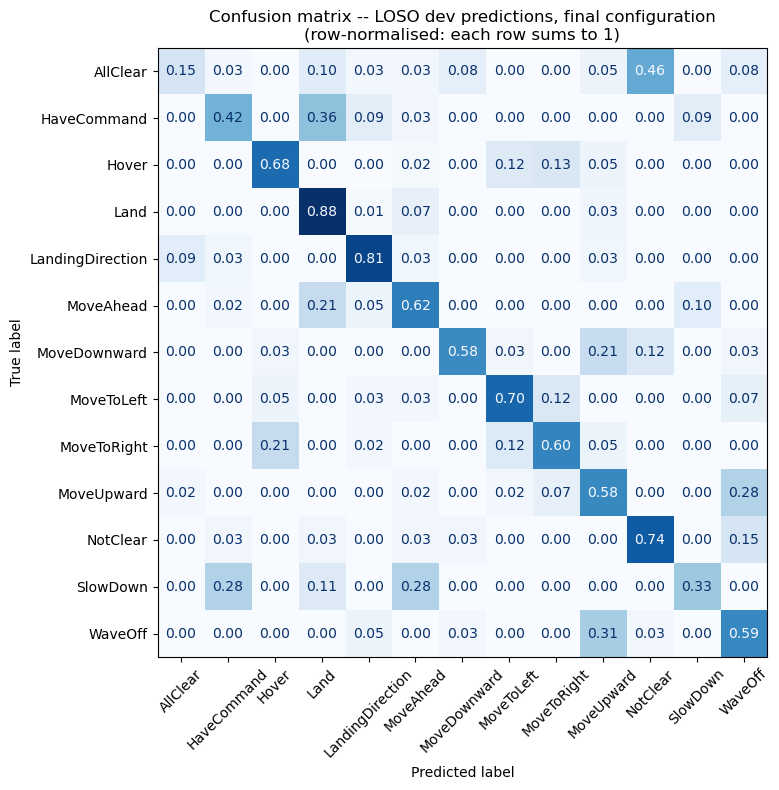

                  precision    recall  f1-score   support

        AllClear       0.60      0.15      0.24        39
     HaveCommand       0.50      0.42      0.46        33
           Hover       0.77      0.68      0.73        60
            Land       0.72      0.88      0.79        86
LandingDirection       0.70      0.81      0.75        32
       MoveAhead       0.53      0.62      0.57        42
    MoveDownward       0.79      0.58      0.67        33
      MoveToLeft       0.67      0.70      0.68        40
     MoveToRight       0.61      0.60      0.60        42
      MoveUpward       0.45      0.58      0.51        43
        NotClear       0.52      0.74      0.61        34
        SlowDown       0.63      0.33      0.44        36
         WaveOff       0.49      0.59      0.53        39

        accuracy                           0.62       559
       macro avg       0.61      0.59      0.58       559
    weighted avg       0.63      0.62      0.61       559



In [49]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true_final, y_pred_final, display_labels=CLASS_NAMES, xticks_rotation=45,
    cmap='Blues', colorbar=False, ax=ax, normalize='true', values_format='.2f')
ax.set_title('Confusion matrix -- LOSO dev predictions, final configuration\n(row-normalised: each row sums to 1)')
plt.tight_layout(); plt.show()

print(classification_report(y_true_final, y_pred_final, target_names=CLASS_NAMES, zero_division=0))

**Class results.** The lowest scores occur in several low movement gestures.

`AllClear` has recall 0.15 and F1 0.24. `SlowDown` has recall 0.33 and F1 0.44. `HaveCommand` has
F1 0.46. `MoveUpward` has F1 0.51. The highest F1 values are 0.79 for `Land`, 0.75 for
`LandingDirection`, 0.73 for `Hover`, and 0.68 for `MoveToLeft`.

The directional classes are not always the most difficult classes. `MoveToLeft` and `MoveToRight`
are in the middle of the class results. Several static classes perform worse. Maximum aggregation
may provide less information for gestures with little movement.

Two safety checks are important. `WaveOff` recall is 0.59 on the development folds and 0.35 on the
locked test set. `MoveToRight` recall is 0.60 on development and 0.24 on the test set. These results
do not meet the class recall target of 0.50 on the test set.


In [50]:
# Safety-weighted error rate (defined in Section 3) on the same predictions.
sw_error = safety_weighted_error_rate(y_true_final, y_pred_final)
plain_error = (y_true_final != y_pred_final).mean()
print(f'Plain error rate:            {plain_error:.3f}')
print(f'Safety-weighted error rate:  {sw_error:.3f}  (weight={SAFETY_WEIGHT}x on WaveOff-missed / L-R swap)')

Plain error rate:            0.381
Safety-weighted error rate:  0.567  (weight=5.0x on WaveOff-missed / L-R swap)


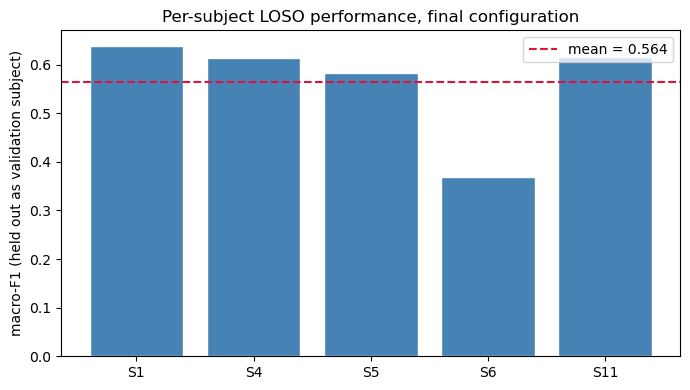

Per-subject macro-F1: {np.str_('S1'): np.float64(0.639), np.str_('S4'): np.float64(0.613), np.str_('S5'): np.float64(0.582), np.str_('S6'): np.float64(0.368), np.str_('S11'): np.float64(0.615)}


In [51]:
# Per-subject spread -- does performance hold up evenly across the 5 LOSO
# subjects, or does one held-out person collapse the average?
fig, ax = plt.subplots(figsize=(7, 4))
subj_f1 = {s: f1_final[i] for i, (s, _, _) in enumerate(make_loso_folds())}
ax.bar(subj_f1.keys(), subj_f1.values(), color='steelblue', edgecolor='white')
ax.axhline(f1_final.mean(), color='crimson', linestyle='--', label=f'mean = {f1_final.mean():.3f}')
ax.set_ylabel('macro-F1 (held out as validation subject)')
ax.set_title('Per-subject LOSO performance, final configuration')
ax.legend()
plt.tight_layout(); plt.show()
print('Per-subject macro-F1:', {s: round(v, 3) for s, v in subj_f1.items()})

**Subject results.** Performance varies between held out subjects.

| Held out subject | macro-F1 |
|---|---|
| S1 | 0.639 |
| S11 | 0.615 |
| S4 | 0.613 |
| S5 | 0.582 |
| **S6** | **0.368** |

Four subjects score between 0.582 and 0.639. S6 scores 0.368. The difference between S6 and the
next lowest subject is 0.214. The mean score therefore does not describe every new subject.

The final model also has a larger fold standard deviation than SafeAug and the frozen Stage A model.
The settings selected on S1 improve some folds and reduce performance on S6. This supports the use of
more than one fold for parameter selection.


213 / 559 LOSO dev instances misclassified (38.1%)


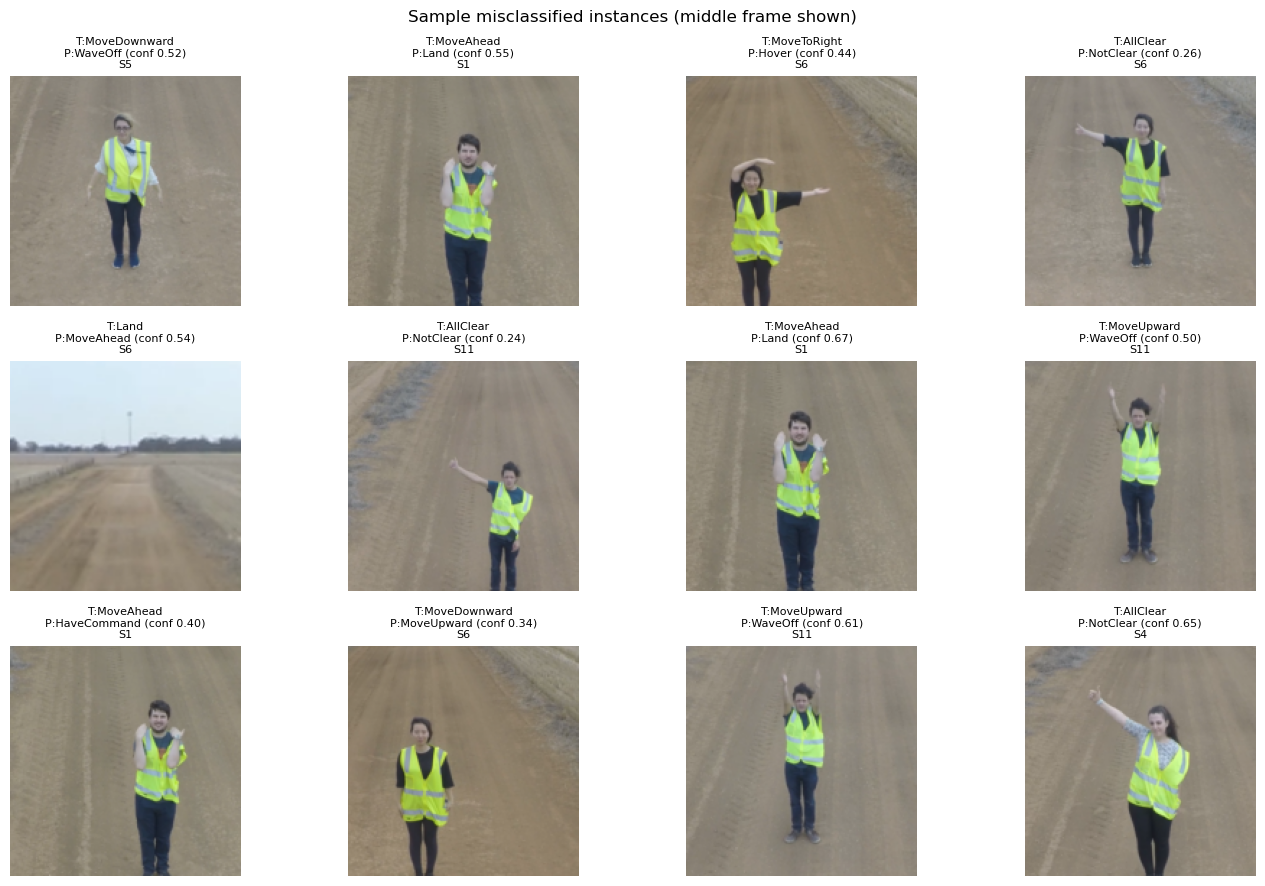

In [52]:
# Misclassified instances -- inspect the actual images, not just the numbers.
wrong = np.where(y_true_final != y_pred_final)[0]
print(f'{len(wrong)} / {len(y_true_final)} LOSO dev instances misclassified '
      f'({len(wrong)/len(y_true_final)*100:.1f}%)')

n_show = min(12, len(wrong))
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=n_show, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, w in zip(axes.flat, show):
    inst = idx_final[w]
    ax.imshow(frames_u8[inst, 2])   # middle frame as a representative thumbnail
    ax.set_title(f'T:{CLASS_NAMES[y_true_final[w]]}\nP:{CLASS_NAMES[y_pred_final[w]]} '
                 f'(conf {conf_final[w]:.2f})\n{subj_final[w]}', fontsize=8)
    ax.axis('off')
for ax in axes.flat[n_show:]:
    ax.axis('off')
plt.suptitle('Sample misclassified instances (middle frame shown)')
plt.tight_layout(); plt.show()

**Error examples.** The model makes 213 errors across 559 development instances.
This is 38.1% of the instances.

Many errors occur between gestures with similar poses. `AllClear`, `HaveCommand`, and `SlowDown`
are confused with each other. `MoveUpward` and `MoveDownward` are also confused when the sampled
frames show an intermediate arm position. Five frames may not contain the complete movement in these
cases.

Some `MoveToLeft` and `MoveToRight` examples have a clear arm position but are still confused. The
model does not consistently use the side of the gesture. This error can produce an incorrect movement
command.


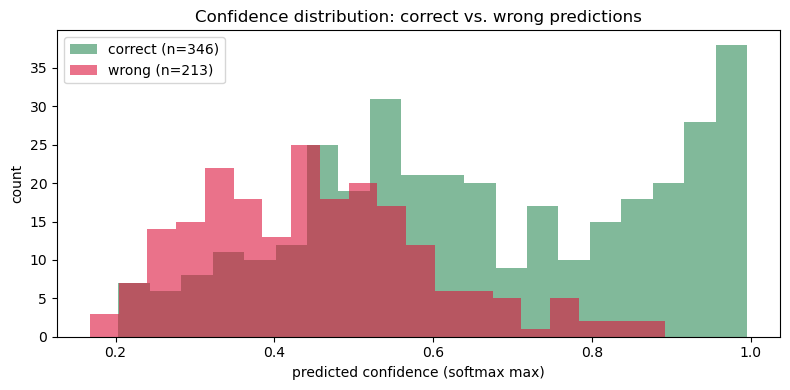

Mean confidence when correct: 0.665
Mean confidence when wrong:   0.451
High-confidence wrong predictions (conf > 0.9): 0 / 213


In [53]:
# Confidence calibration -- is the model appropriately less confident when wrong?
correct_conf = conf_final[y_true_final == y_pred_final]
wrong_conf = conf_final[y_true_final != y_pred_final]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correct_conf, bins=20, alpha=0.6, label=f'correct (n={len(correct_conf)})', color='seagreen')
ax.hist(wrong_conf, bins=20, alpha=0.6, label=f'wrong (n={len(wrong_conf)})', color='crimson')
ax.set_xlabel('predicted confidence (softmax max)'); ax.set_ylabel('count')
ax.set_title('Confidence distribution: correct vs. wrong predictions')
ax.legend()
plt.tight_layout(); plt.show()

print(f'Mean confidence when correct: {correct_conf.mean():.3f}')
print(f'Mean confidence when wrong:   {wrong_conf.mean():.3f}')
print(f'High-confidence wrong predictions (conf > 0.9): {(wrong_conf > 0.9).sum()} / {len(wrong_conf)}')

**Confidence results.** Correct predictions have higher confidence on average.

- Mean confidence is 0.665 for correct predictions.
- Mean confidence is 0.451 for incorrect predictions.
- None of the 213 errors has confidence above 0.90.

A confidence threshold could convert some predictions into abstentions. This would reduce the number
of incorrect actions but would also reduce recall. An abstention also requires a safe fallback rule.
These confidence results use subjects from the original recording conditions. Section 9 tests a new
camera and room.


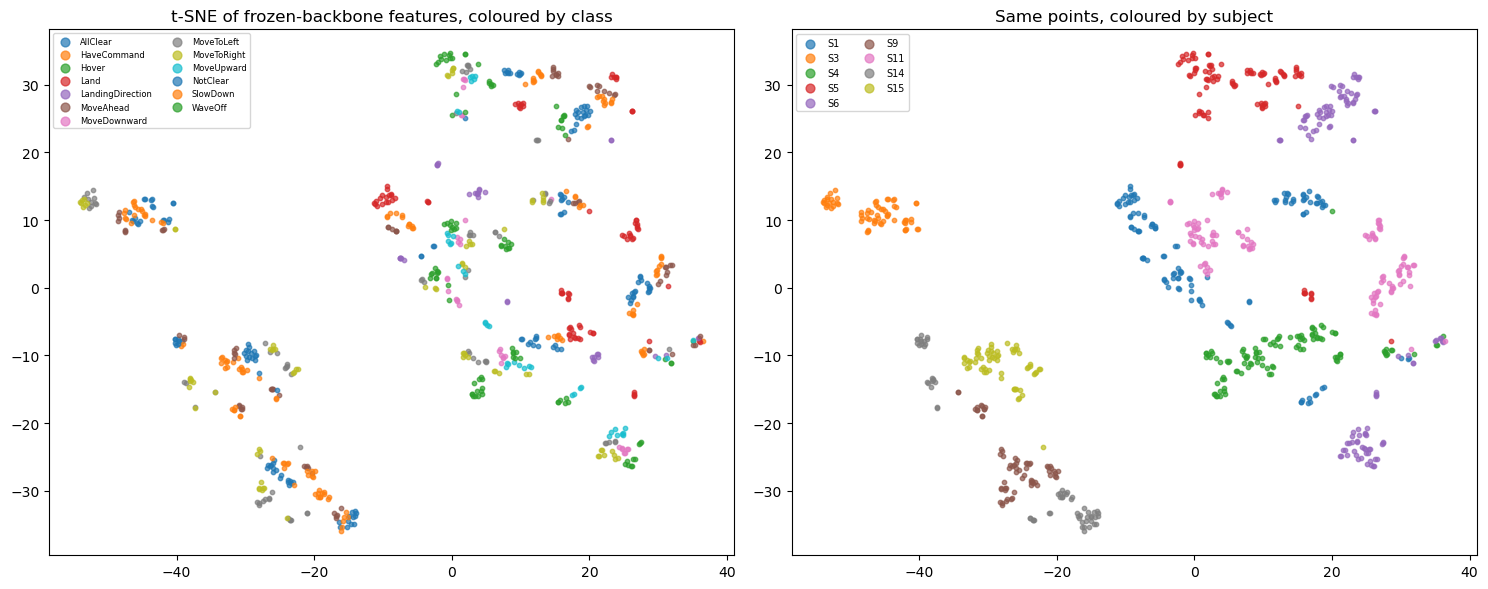

In [54]:
# t-SNE on the frozen ImageNet-pretrained features (Stage A, Section 6) --
# does the *generic* pretrained representation already separate gestures
# and/or cluster by subject, before any task-specific training at all?
from sklearn.manifold import TSNE

dev_idx = np.where(dev_mask)[0]
mean_frame_feats = late_features[dev_idx].mean(axis=1)     # (n_dev, 1280) -- average over the 5 frames

set_seed()
tsne = TSNE(n_components=2, random_state=SEED, init='pca', perplexity=30)
feats_2d = tsne.fit_transform(mean_frame_feats)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for c in range(NUM_CLASSES):
    m = labels[dev_idx] == c
    axes[0].scatter(feats_2d[m, 0], feats_2d[m, 1], s=10, label=CLASS_NAMES[c], alpha=0.7)
axes[0].set_title('t-SNE of frozen-backbone features, coloured by class')
axes[0].legend(fontsize=6, ncol=2, markerscale=2)

for s in sorted(set(subjects[dev_idx]), key=lambda x: int(x[1:])):
    m = subjects[dev_idx] == s
    axes[1].scatter(feats_2d[m, 0], feats_2d[m, 1], s=10, label=s, alpha=0.7)
axes[1].set_title('Same points, coloured by subject')
axes[1].legend(fontsize=7, ncol=2, markerscale=2)
plt.tight_layout(); plt.show()

**Feature visualisation.** The frozen representation separates subjects more
clearly than gesture classes.

The class coloured plot has no clear gesture groups. The subject coloured plot contains several
separate subject groups. The frozen features therefore contain strong subject and scene information.

This is consistent with three earlier results. The random split scores 0.867 because the same
subjects occur in training and validation. The subject disjoint split scores 0.534. Cropping improves
macro-F1 by 0.178 because it removes some background information.

The plot uses frozen backbone features before the fusion head is trained. It supports the need for
more subjects but does not show the final representation directly.


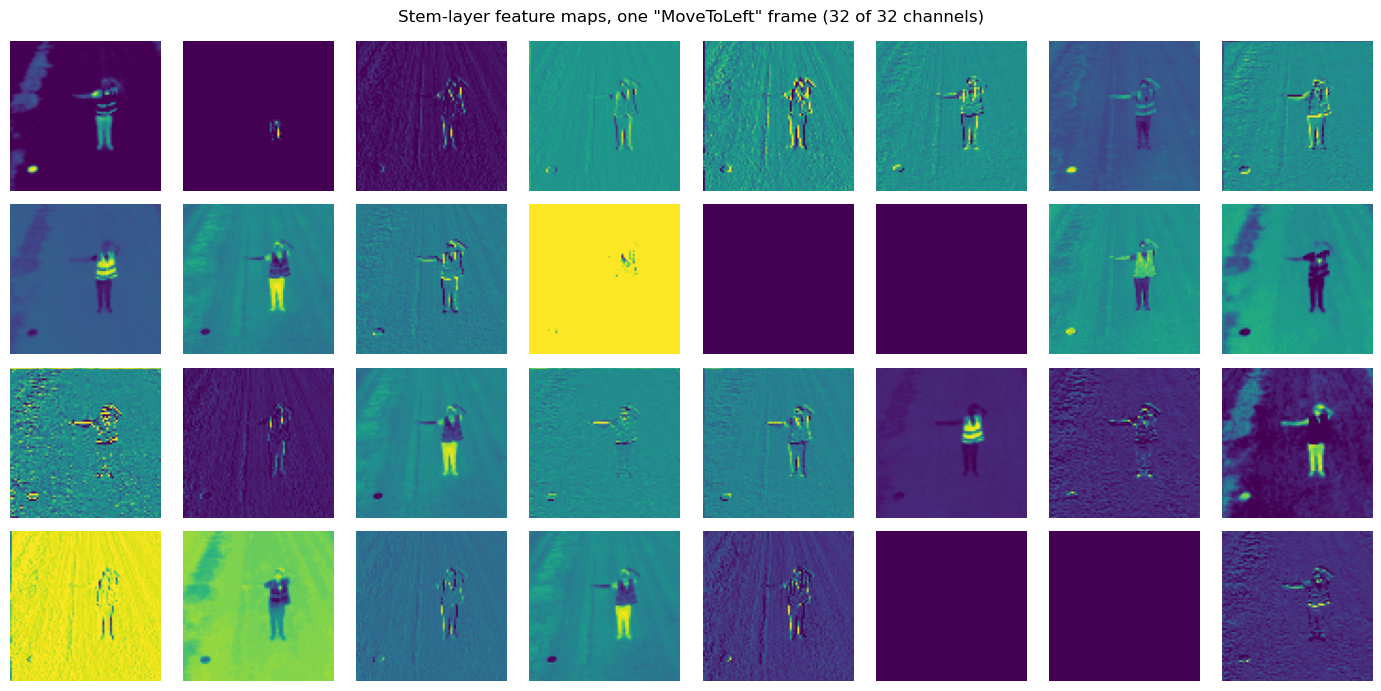

In [55]:
# Forward-hook feature maps -- what does an early MobileNetV2 filter actually
# respond to on one of our gesture frames? Same technique as the Week 4
# lecture notebook (cells 50-55), applied to the frozen pretrained backbone.
activation = {}

def save_activation(name):
    def hook(module, inp, out):
        activation[name] = out.detach().cpu()
    return hook

first_block = frozen_encoder.features[0]                 # Conv2d+BN+ReLU6 stem
handle = first_block.register_forward_hook(save_activation('stem'))

example_inst = np.where(labels == CLASS_TO_IDX['MoveToLeft'])[0][0]
example_img = normalize(torch.from_numpy(frames_u8[example_inst, 2]).permute(2, 0, 1).float().to(device) / 255.0)
frozen_encoder.eval()
with torch.no_grad():
    _ = frozen_encoder(example_img.unsqueeze(0))
handle.remove()

fmaps = activation['stem'][0]                              # (32, H', W')
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i].numpy(), cmap='viridis')
    ax.axis('off')
plt.suptitle(f'Stem-layer feature maps, one "{CLASS_NAMES[labels[example_inst]]}" frame (32 of 32 channels)')
plt.tight_layout(); plt.show()

**Stem feature maps.** Most first layer channels respond to the subject outline.
Several channels show the arms and torso. Other channels respond to the high visibility vest. The
road and horizon have weaker responses in this example.

The backbone can locate the subject after cropping. The later pooled representation still contains
more subject and scene structure than gesture structure, as shown by the feature visualisation. This
figure is a supporting check and is not used as the main performance evidence.


---
## 9. Final evaluation

The locked test set is used after the architecture and training settings are selected. It contains
subjects S12 and S13. No further model changes are made after this evaluation.


In [56]:
DEV_SUBJECTS_ALL = LOSO_DEV_SUBJECTS + TRAIN_ONLY_SUBJECTS   # all 9 non-test subjects
final_train_idx = np.where(np.isin(subjects, DEV_SUBJECTS_ALL))[0]
test_idx = np.where(test_mask)[0]
print(f'Refitting on all {len(final_train_idx)} development instances '
      f'({len(DEV_SUBJECTS_ALL)} subjects); certifying on {len(test_idx)} locked test instances '
      f'({LOCKED_TEST_SUBJECTS}).')

@torch.no_grad()
def evaluate_and_collect(model, loader):
    """Run `model` over `loader` and return (y_true, y_pred, confidence) as
    numpy arrays, in loader order. Shared by the test-set certification below
    and the webcam evaluation that follows it."""
    model.eval()
    all_true, all_pred, all_conf = [], [], []
    for xb, yb in loader:
        xb = xb.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP_ENABLED):
            logits = model(xb)
        probs = torch.softmax(logits.float(), dim=1)
        conf, pred = probs.max(dim=1)
        all_true.append(yb); all_pred.append(pred.cpu()); all_conf.append(conf.cpu())
    return torch.cat(all_true).numpy(), torch.cat(all_pred).numpy(), torch.cat(all_conf).numpy()


_LOAD_TEST_SET_GUARD = 'test_set_opened'
assert _LOAD_TEST_SET_GUARD not in globals() or not globals()[_LOAD_TEST_SET_GUARD], \
    'Locked test set has already been opened once in this run -- refusing to touch it again.'

with section('Final refit on full development set'):
    set_seed()
    final_model = build_late().to(device)
    train_loader = DataLoader(InstanceDataset(final_train_idx, augment=safe_augment), batch_size=32,
                               shuffle=True, generator=g)
    criterion = nn.CrossEntropyLoss()

    final_model.encoder.freeze()
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()), lr=1e-3)
    for _ in range(3):
        run_epoch(final_model, train_loader, criterion, opt)

    final_model.encoder.unfreeze_from(final_model.encoder.n_blocks - 4)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, final_model.parameters()),
                            lr=1e-4, weight_decay=best_wd)
    for _ in range(8):
        run_epoch(final_model, train_loader, criterion, opt)
    print('Final model trained on all development data.')

Refitting on all 819 development instances (9 subjects); certifying on 240 locked test instances (['S12', 'S13']).
--- Final refit on full development set ---
Final model trained on all development data.
[Final refit on full development set finished in 0.9 min]


In [57]:
with section('ONE-SHOT locked test evaluation'):
    test_loader = DataLoader(InstanceDataset(test_idx, augment=None), batch_size=64,
                              shuffle=False)
    test_true, test_pred, test_conf = evaluate_and_collect(final_model, test_loader)
    test_set_opened = True   # guard: this cell must never run twice

test_f1 = _f1_score(test_true, test_pred, average='macro', zero_division=0)
test_sw_error = safety_weighted_error_rate(test_true, test_pred)

print('=' * 60)
print('FINAL TEST SET CERTIFICATION  (S12, S13 -- never touched before this cell)')
print('=' * 60)
print(f'Test macro-F1:              {test_f1:.3f}')
print(f'Test accuracy:              {(test_true == test_pred).mean():.3f}')
print(f'Test safety-weighted error: {test_sw_error:.3f}')
print(f'LOSO dev macro-F1 (Sec. 7): {mean_std(f1_final)}')
print(f'Gap (test - dev mean):      {test_f1 - f1_final.mean():+.3f}')
print(f'Target from Section 3:      macro-F1 >= 0.75  ->  {"MET" if test_f1 >= 0.75 else "NOT MET"}')
print('=' * 60)

print(classification_report(test_true, test_pred, target_names=CLASS_NAMES, zero_division=0))

--- ONE-SHOT locked test evaluation ---
[ONE-SHOT locked test evaluation finished in 0.1 min]
FINAL TEST SET CERTIFICATION  (S12, S13 -- never touched before this cell)
Test macro-F1:              0.618
Test accuracy:              0.671
Test safety-weighted error: 0.613
LOSO dev macro-F1 (Sec. 7): 0.564 +/- 0.099
Gap (test - dev mean):      +0.055
Target from Section 3:      macro-F1 >= 0.75  ->  NOT MET
                  precision    recall  f1-score   support

        AllClear       0.12      0.08      0.10        12
     HaveCommand       0.71      0.62      0.67        16
           Hover       0.74      0.77      0.76        22
            Land       0.86      1.00      0.92        36
LandingDirection       1.00      0.94      0.97        16
       MoveAhead       0.59      0.89      0.71        19
    MoveDownward       0.59      1.00      0.74        13
      MoveToLeft       0.67      0.59      0.62        17
     MoveToRight       0.80      0.24      0.36        17
      MoveU

**Locked test result.** The result is within the variation observed across the
development folds.

| Dataset | macro-F1 |
|---|---|
| Development estimate | 0.564 ± 0.099 |
| **Locked test set with S12 and S13** | **0.618** |
| Difference | **+0.055** |

The test score is 0.055 above the development mean and within one development standard deviation.
The subject disjoint development estimate is therefore consistent with the locked test result. The
random split result of 0.867 is not representative of new subjects.

The test set contains 240 instances across 13 classes. This is about 18 instances per class. The
score has sampling uncertainty. It does not meet the target of 0.75.


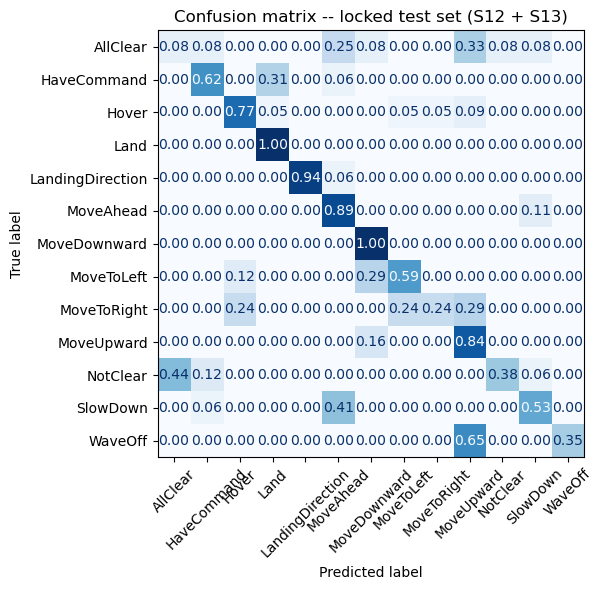

In [58]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    test_true, test_pred, display_labels=CLASS_NAMES, xticks_rotation=45,
    cmap='Blues', colorbar=False, ax=ax, normalize='true', values_format='.2f')
ax.set_title(f'Confusion matrix -- locked test set ({" + ".join(LOCKED_TEST_SUBJECTS)})')
plt.tight_layout(); plt.show()

### Independent evidence: webcam clips

The webcam clips show a different person in a bedroom. They use a different camera, room, and
lighting. The purpose is to test the model under recording conditions that are absent from the
assignment dataset.

The folder structure matches the assignment dataset. This allows the same parser and decoder to be
used.

```
Assignment 1/webcam_clips/<ClassName>/<attempt_name>/1.png ... 5.png
```

`<ClassName>` must match one of the 13 class folders. Each attempt contains five frames named
`1.png` to `5.png`. The frames cover the gesture from start to finish. If the folder is missing or
empty, the cell reports this and the notebook continues.


In [59]:
WEBCAM_DIR = ASSIGNMENT_ROOT / 'webcam_clips'

webcam_records = parse_instances(WEBCAM_DIR) if WEBCAM_DIR.exists() else []
unknown_class = [r for r in webcam_records if r['class'] not in CLASS_TO_IDX]
if unknown_class:
    print('WARNING -- these folders do not match any of the 13 class names and will be skipped:',
          sorted(set(r['class'] for r in unknown_class)))
webcam_records = [r for r in webcam_records if r['class'] in CLASS_TO_IDX]

print(f'Found {len(webcam_records)} webcam instance(s) in {WEBCAM_DIR}')

if not webcam_records:
    print('No webcam clips yet. See the format description above -- once clips are added under '
          'webcam_clips/<ClassName>/<attempt>/1..5.png, re-run this cell (and only this cell) to '
          'get the independent-evidence numbers below. Nothing else in the notebook depends on this.')
else:
    # Same decoder, same ACTIVE_PIPELINE chosen in Section 6, so the webcam clips
    # get exactly the preprocessing the deployed model expects.
    webcam_frames = decode_instances(webcam_records, pipelines=(ACTIVE_PIPELINE,))[ACTIVE_PIPELINE]
    webcam_labels = np.array([CLASS_TO_IDX[r['class']] for r in webcam_records])

Found 24 webcam instance(s) in /home/ec2-user/SageMaker/webcam_clips


In [60]:
if webcam_records:
    import warnings

    class _WebcamDataset(Dataset):
        def __init__(self, frames, labels_arr):
            self.frames, self.labels_arr = frames, labels_arr
        def __len__(self):
            return len(self.labels_arr)
        def __getitem__(self, i):
            imgs = torch.from_numpy(self.frames[i]).permute(0, 3, 1, 2).float() / 255.0
            return normalize(imgs), int(self.labels_arr[i])

    webcam_loader = DataLoader(_WebcamDataset(webcam_frames, webcam_labels), batch_size=32, shuffle=False)
    wc_true, wc_pred, wc_conf = evaluate_and_collect(final_model, webcam_loader)
    wc_classes_present = sorted(set(wc_true))

    with warnings.catch_warnings():
        warnings.filterwarnings(
            'ignore',
            message='The number of unique classes is greater than 50% of the number of samples.*',
            category=UserWarning,
        )
        wc_macro_f1 = _f1_score(
            wc_true,
            wc_pred,
            average='macro',
            labels=wc_classes_present,
            zero_division=0,
        )
        wc_report = classification_report(
            wc_true,
            wc_pred,
            labels=wc_classes_present,
            target_names=[CLASS_NAMES[c] for c in wc_classes_present],
            zero_division=0,
        )

    print(f'Webcam macro-F1 (classes present only): {wc_macro_f1:.3f}')
    print(f'Webcam accuracy: {(wc_true == wc_pred).mean():.3f}  ({len(wc_true)} instances)')
    print(wc_report)


Webcam macro-F1 (classes present only): 0.118
Webcam accuracy: 0.208  (24 instances)
                  precision    recall  f1-score   support

        AllClear       0.00      0.00      0.00         2
     HaveCommand       0.00      0.00      0.00         2
           Hover       0.00      0.00      0.00         1
            Land       0.00      0.00      0.00         1
LandingDirection       0.00      0.00      0.00         1
       MoveAhead       0.00      0.00      0.00         1
    MoveDownward       0.00      0.00      0.00         2
      MoveToLeft       0.50      0.50      0.50         2
     MoveToRight       0.00      0.00      0.00         3
      MoveUpward       0.13      1.00      0.24         2
        NotClear       0.00      0.00      0.00         2
        SlowDown       0.67      1.00      0.80         2
         WaveOff       0.00      0.00      0.00         3

        accuracy                           0.21        24
       macro avg       0.10      0.19      

**Webcam result.** Macro-F1 is 0.118. Accuracy is 0.208.

The webcam set contains 24 attempts across all 13 gestures. It shows one person indoors with a
wide angle webcam. The camera is at eye level. The background is a plain wall. The person does not
wear a high visibility vest. The assignment data shows eleven people outdoors on a dirt road from a
higher camera position.

| Dataset | macro-F1 | Accuracy |
|---|---|---|
| Locked test set | 0.618 | 0.671 |
| Webcam set | **0.118** | **0.208 (5 of 24)** |

`SlowDown` has F1 of 0.80 and `MoveToLeft` has F1 of 0.50. Nine classes have F1 of zero.
`MoveUpward` has recall 1.00 and precision 0.13. The model predicts this class for many other
gestures. `WaveOff` has F1 of zero for all three attempts.

The test changes the person, camera, room, clothing, lighting, and viewpoint at the same time. It
does not measure the effect of each factor separately. It also contains only 24 attempts. Per class
results are therefore uncertain. The lower overall score still shows poor performance under these
new conditions.


---
## Final judgement

| Question | Evidence | Conclusion |
|---|---|---|
| Is the macro-F1 target of 0.75 met? | locked test macro-F1 is 0.618 | No |
| Is performance consistent between subjects? | subject macro-F1 ranges from 0.368 to 0.639 | No |
| Are the selected safety errors controlled? | test recall is 0.35 for `WaveOff` and 0.24 for `MoveToRight` | No |
| Can confidence support abstention? | correct mean is 0.665, error mean is 0.451, and no error is above 0.90 | Yes, with a safe fallback |
| Does the model work in the webcam setting? | webcam macro-F1 is 0.118 | No |
| What is the effect of a random subject split? | random split is 0.867 and subject disjoint split is 0.534 | increase of 0.332 |
| Is the model small enough for the hardware? | 2.56 million parameters and 5.0 ms per instance | Yes |

**Recommendation: do not deploy the model in a safety critical role.**

The locked test macro-F1 is below the target. Recall is also low for `WaveOff` and `MoveToRight`.
Performance varies between subjects and falls on the webcam clips. The safety weighted error rate is
0.613. The unweighted error rate is 0.381.

The first next step is to collect data from more people and recording conditions. The model also
needs an abstention rule with a safe response. More examples of `WaveOff` and directional gestures
are required.

### Limitations

- The assignment data contains eleven people from one recording setting.
- The webcam set contains one person and 24 attempts. Several conditions change together.
- Five sampled frames can miss part of the gesture movement.
- The motion crop uses the centre crop for 50.8% of the instances.
- Hyperparameters were shortlisted on one fold.
- The locked test set contains two subjects and 240 instances.


---
# Part B: Deployment recommendation

- **Do not ship the model for autonomous use.** Locked test macro-F1 is 0.618. This is below the
  target of 0.750.

- **The model has important safety errors.** Test recall is 0.35 for `WaveOff` and 0.24 for
  `MoveToRight`. These errors can allow an unsafe approach or an incorrect movement.

- **Results change between people.** Macro-F1 ranges from 0.368 to 0.639 across five unseen
  development subjects. Performance for a new receiver cannot be predicted reliably.

- **Results also change outside the assignment setting.** Webcam accuracy is 0.208 and macro-F1 is
  0.118 for a different person, camera, room, and lighting.

- **The 0.867 random split result should not be used for the decision.** The same subjects appear in
  training and validation. The subject disjoint result is 0.534 with the same model.

- **A confidence rule may reduce incorrect actions.** No development error has confidence above
  0.90. The system must hold position or request human confirmation when confidence is low.

- **More testing is required before deployment.** Collect data from more signallers, locations,
  cameras, clothing, lighting, and viewpoints. Evaluate each new version with subject disjoint data.

- **Use a supervised pilot only after these controls are added.** A human must confirm each command.
  Responsibility for missed or incorrect signals must be defined before field use.
